# MCP Trip Planner: Intake → Plan → Inquire / Revise / Approve

A LangGraph pipeline that turns a free-text trip request into a researched travel plan, using **MCP servers** for every external capability: live flights (Ignav), destination research (Tavily) and file output (official filesystem server). A human-in-the-loop decision step lets the user keep the plan, change the request, or approve it and save it as a `.txt` file. State is kept per `thread_id`, so the graph can pause at a question and resume later.

## Flow

```
START
  │
  ▼
[1] INTAKE ── LLM + Pydantic → TravelDetails, computes missing fields
  │
  ├─ missing info ──► [2] CLARIFY (interrupt: ask the user) ──► back to INTAKE
  │
  ▼  complete
[3] PLANNING ── one agent: airports → flights (Ignav) → hotels, activities,
  │             events, visa, transport (Tavily) → budget snapshot
  ▼
[4] HUMAN DECISION (interrupt) ── user chooses:
  │
  ├─ inquire ──► END            (plan shown, nothing saved)
  ├─ revise  ──► back to INTAKE (user's change message is added to the conversation)
  └─ approve ──► [5] WRITER ──► <destination>.txt in the sandbox ──► END
```

## The three decisions

| Action | Resume payload | Route | Ends with |
|---|---|---|---|
| Inquire | `{"action": "inquire"}` | Decision → END | Plan on screen, nothing saved |
| Revise | `{"action": "revise", "message": "..."}` | Decision → Intake → Planning → Decision | New plan, back at the decision |
| Approve | `{"action": "approve"}` | Decision → Writer → END | `saved_filename` in the sandbox folder |

Clarify answers are resumed with `Command(resume={"message": "..."})`. Invalid input (empty revise message, unknown action, empty answer) re-asks with an `error` field instead of raising.

## Nodes

| # | Node | Type | Job | Tools | Writes to state |
|---|---|---|---|---|---|
| 1 | Intake | LLM, structured output | Read the whole conversation, fill `TravelDetails`, list missing fields | none | `travel_framed_details`, `missing_info` |
| 2 | Clarify | interrupt | Ask for the missing fields | none | `reframed_question` |
| 3 | Planning | agent | Resolve airports, search flights, research the destination, write the plan | `airports_mcp_search_tool`, `flights_mcp_search_tool`, `tavily_mcp_search_tool` | `travel_search_result` |
| 4 | Human decision | interrupt | Inquire, revise or approve | none | `reframed_question` (on revise) |
| 5 | Writer | agent | Save the approved plan without changing facts | `filesystem_write_mcp_tool` | `saved_file`, `saved_filename` |

## MCP servers and tools

| Server | Transport | Tool used | Used by |
|---|---|---|---|
| Ignav | remote, bearer token | `ignav_search_airports`, `ignav_search_flights` | Planning |
| Tavily | remote, key in URL | `tavily_tavily_search` | Planning |
| Filesystem (`@modelcontextprotocol/server-filesystem`) | local, via `npx` | `filesystem_write_file` | Writer |

Tools are discovered at runtime with `MCPAdapter.list_tools()` and wrapped as LangChain tools. The servers expose more tools than this (for example `search_cheapest_dates`, `tavily_extract`, `read_file`); only the ones above are given to agents.

## State

`question`, `reframed_question`, `travel_framed_details`, `missing_info`, `travel_search_result`, `saved_file`, `saved_filename`, `messages`

## Key design points

- **Structured intake.** Pydantic validators reject non-ISO dates and a return date before departure. Vague dates ("next Friday") are left empty so the graph asks instead of guessing.
- **Source rules in the planning prompt.** Flight data may come only from Ignav, airport codes only from the airport tool, Tavily is forbidden for flights, prices are never estimated, currencies are never converted, and visa research is skipped when nationality is unknown.
- **Least-privilege tools.** The planning agent cannot write files. The writer can only write, and the write tool refuses any path outside the sandbox folder.
- **Human in the loop.** `interrupt()` pauses the graph; `Command(resume=...)` continues it. A checkpointer (`MemorySaver`) and a `thread_id` are required.
- **MCP connections stay open** in one long-running task and are closed explicitly with `close_mcp()`.


## Code layout

`config.py` (env + MCP config) · `schemas.py` (Pydantic models, state) · `prompts.py` · `tools.py` (MCP client + tools) · `pipeline.py` (nodes + graph) · `streamlit_app.py` (UI)

In [1]:
# =========================
# Standard library
# =========================

import os
import re
import json
import asyncio
import datetime
import logging
import urllib.request

from contextlib import AsyncExitStack
from pathlib import Path
from typing import (
    Annotated,
    Literal,
    Sequence,
    TypedDict,
)


# =========================
# Third-party utilities
# =========================

import certifi
import requests

from dotenv import load_dotenv

from pydantic import (
    BaseModel,
    Field,
    field_validator,
    model_validator,
)


# =========================
# OpenAI / LangChain models
# =========================

from langchain_openai import (
    ChatOpenAI,
    OpenAIEmbeddings,
)


# =========================
# LangChain core
# =========================

from langchain_core.messages import (
    AnyMessage,
    BaseMessage,
    HumanMessage,
    AIMessage,
    SystemMessage,
)

from langchain_core.prompts import ChatPromptTemplate
from langchain_core.tools import tool


# =========================
# LangChain agents
# =========================

from langchain.agents import create_agent

from langchain.agents.middleware import (
    HumanInTheLoopMiddleware,
)


# =========================
# MCP
# =========================

from langchain.mcp import MCPAdapter
from mcp.server import MCPServer


# =========================
# LangGraph
# =========================

from langgraph.graph import (
    StateGraph,
    MessagesState,
    START,
    END,
)

from langgraph.graph.message import add_messages

from langgraph.types import (
    Command,
    interrupt,
)


# =========================
# LangGraph checkpointing
# =========================

from langgraph.checkpoint.memory import (
    InMemorySaver,
    MemorySaver,
)

from langgraph.checkpoint.postgres import PostgresSaver

from langgraph.checkpoint.serde.jsonplus import (
    JsonPlusSerializer,
)


# =========================
# Environment setup
# =========================

load_dotenv()

# Disable LangSmith tracing
os.environ["LANGSMITH_TRACING"] = "false"

# Disable Langfuse tracing
os.environ["LANGFUSE_TRACING_ENABLED"] = "false"


# =========================
# MCP logging
# =========================

logging.getLogger("fastmcp").setLevel(logging.WARNING)

logging.getLogger(
    "fastmcp.server.providers.proxy"
).setLevel(logging.WARNING)


# =========================
# SSL setup
# =========================

# Uncomment if needed
# os.environ["SSL_CERT_FILE"] = certifi.where()
# os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

/var/folders/pk/nk0t185511z8g6hmxr_bhkfw0000gn/T/ipykernel_64262/3654176080.py:81: LangChainBetaWarning: `langchain.mcp` is in beta. It is actively being worked on, so the API may change.
  from langchain.mcp import MCPAdapter


In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

#os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")
os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["IGNAV_API_KEY"]=os.getenv("IGNAV_API_KEY")


In [3]:
TAVILY_API_KEY = os.getenv("TAVILY_API_KEY")
IGNAV_API_KEY = os.getenv("IGNAV_API_KEY")

### DEMONSTRATION

In [4]:
config = {
    "mcpServers": {
        "ignav": {
            "url": "https://ignav.com/mcp",
            "headers": {
                "Authorization": f"Bearer {IGNAV_API_KEY}"
            }
        }
    }
}

In [5]:
## DETAILS NEEDED FOR FLIGHT
## LLM structure

class FlightDetails(BaseModel):
    origin: str | None = Field(
        default=None,
        description=(
            "The city, airport, metro area, or country the user wants to depart from. "
            "Do not invent an IATA code if the user did not provide one."
        ),
    )

    destination: str | None = Field(
        default=None,
        description="The city, country, municipality, or travel destination the user wants to visit.",
    )

    departure_date: str | None = Field(
        default=None,
        description="Departure date in YYYY-MM-DD format if known.",
    )

    return_date: str | None = Field(
        default=None,
        description=(
            "Return date in YYYY-MM-DD format. "
            "Use None when this is a one-way trip or the date is not yet known."
        ),
    )

    trip_type: Literal["one_way", "round_trip", "unknown"] = Field(
        default="unknown",
        description="Whether the user wants a one-way or round-trip flight.",
    )

    # fail fast on bad date formats before they reach Ignav
    @field_validator("departure_date", "return_date")
    @classmethod
    def check_iso_date(cls, v):
        if v is not None:
            datetime.date.fromisoformat(v)  # raises on bad format
        return v

    # return must be after departure
    @model_validator(mode="after")
    def check_date_order(self):
        if self.departure_date and self.return_date:
            if self.return_date < self.departure_date:  # ISO strings sort correctly
                raise ValueError("return_date must be after departure_date")
        return self


## TRAVELLER / TRIP DETAILS
class TravelDetails(BaseModel):
    flight: FlightDetails = Field(default_factory=FlightDetails)

    adults: int = Field(default=1, ge=1, description="Number of adult travellers.")

    budget_amount: float | None = Field(
        default=None,
        description="Maximum or approximate trip budget if the user gives one.",
    )

    budget_currency: str | None = Field(
        default=None,
        description="Currency of the budget, such as EUR, USD or GBP.",
    )

    nationality: str | None = Field(
        default=None,
        description=(
            "Traveller nationality/passport country when provided. "
            "Useful for visa and entry requirement research."
        ),
    )

    hotel_preferences: str | None = Field(
        default=None,
        description=(
            "Hotel requirements such as luxury level, neighborhood, "
            "family-friendly, hostel, beach access, etc."
        ),
    )

    interests: list[str] = Field(
        default_factory=list,
        description=(
            "Activities or interests such as museums, nightlife, hiking, "
            "food, beaches, history, shopping, concerts or family activities."
        ),
    )


In [6]:
llm = ChatOpenAI(
    model="gpt-4o",
    temperature=0
)
structured_travel_llm = llm.with_structured_output(TravelDetails)

In [7]:

travel_intake_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            """
You are the travel-intake layer of a travel planning system.

Your only job is to read the traveller's conversation and fill in the
structured travel fields. Do NOT search, recommend, or answer anything.
Another agent with live travel tools will use your output.

Today's date is {today}.

RULES:
- Never invent or guess any detail: dates, budget, nationality, airport codes.
- Keep origin and destination exactly as the user said them
  (if the user says "London", keep "London", not "LHR").
- Use information from the whole conversation, not only the last message.
- Dates must be explicit (day, month and year), written as YYYY-MM-DD.
  Vague dates like "next Friday", "in December" or "end of the month"
  are NOT valid: leave the date as None.
- A date before {today} is not valid: leave it as None.
- trip_type:
  - "round_trip" if a return date is given
  - "one_way" if the user says one-way (return_date stays None)
  - "unknown" if the user says neither
- adults: use the number stated by the user, otherwise 1.
- Fill budget_amount and budget_currency only if the user stated them.
- Fill nationality only if the user stated it.
- Fill hotel_preferences and interests only if the user mentioned them.
- Anything not stated stays None (or an empty list for interests).
""",
        ),
        (
            "human",
            """
Traveller conversation:

{conversation}
""",
        ),
    ]
)

intake_chain = travel_intake_prompt | structured_travel_llm

In [8]:
conversation_text = "User: I want to fly from Cologne to Lisbon on 2026-11-14 and come back 2026-11-21. Budget is 1500 EUR, I like food and history. and im thinking to stay somewhere close to the city or airport"

result = intake_chain.invoke({
    "today": datetime.date.today().isoformat(),
    "conversation": conversation_text,
})

result

TravelDetails(flight=FlightDetails(origin='Cologne', destination='Lisbon', departure_date='2026-11-14', return_date='2026-11-21', trip_type='round_trip'), adults=1, budget_amount=1500.0, budget_currency='EUR', nationality=None, hotel_preferences='close to the city or airport', interests=['food', 'history'])

In [9]:
print(result.adults)
print(result.budget_amount)
print(result.budget_currency)
print(result.hotel_preferences)
print(result.interests)

1
1500.0
EUR
close to the city or airport
['food', 'history']


In [10]:
result

TravelDetails(flight=FlightDetails(origin='Cologne', destination='Lisbon', departure_date='2026-11-14', return_date='2026-11-21', trip_type='round_trip'), adults=1, budget_amount=1500.0, budget_currency='EUR', nationality=None, hotel_preferences='close to the city or airport', interests=['food', 'history'])

In [11]:
print(result.model_dump_json(indent=2)) 

{
  "flight": {
    "origin": "Cologne",
    "destination": "Lisbon",
    "departure_date": "2026-11-14",
    "return_date": "2026-11-21",
    "trip_type": "round_trip"
  },
  "adults": 1,
  "budget_amount": 1500.0,
  "budget_currency": "EUR",
  "nationality": null,
  "hotel_preferences": "close to the city or airport",
  "interests": [
    "food",
    "history"
  ]
}


## Flight & Airport TOOL

In [12]:
async with MCPAdapter(config) as adapter:

    tools = await adapter.list_tools()

    print("Available tools:")

    for tool in tools:
        print(tool.name)

    tool_map = {
        tool.name: tool
        for tool in tools
    }

Available tools:
search_airports
search_flights
search_cheapest_dates


In [13]:
async def get_all_tools():
    async with MCPAdapter(config) as adapter:
        tools = await adapter.list_tools()
        return tools

In [14]:
await get_all_tools()

[StructuredTool(name='search_airports', description='Find airport IATA codes by city, airport name, metro area, or code.', args_schema={'additionalProperties': False, 'properties': {'query': {'description': 'Search query for airport names, city names, or airport codes.', 'title': 'Query', 'type': 'string'}, 'limit': {'default': 5, 'description': 'Maximum number of airport results to return.', 'maximum': 10, 'minimum': 1, 'title': 'Limit', 'type': 'integer'}}, 'required': ['query'], 'title': 'SearchAirportsArgs', 'type': 'object'}, metadata={'mcp': {'tool': {'annotations': {'read_only_hint': True, 'destructive_hint': False, 'open_world_hint': True}, '_meta': {'securitySchemes': [{'type': 'oauth2', 'scopes': ['flights:search']}]}}, 'server': {'name': 'Ignav', 'version': '1.0.0'}}}, handle_tool_error=<function _handle_mcp_tool_error at 0x121136c00>, response_format='content_and_artifact', coroutine=<function as_langchain_tool.<locals>.call_tool at 0x125beb100>),
 StructuredTool(name='sear

In [15]:
from langchain_core.tools import tool
airports_search_tool = None


##create airport tool
async def get_airports_search_tool():
    global airports_search_tool

    if airports_search_tool is not None:
        return

    tools = await get_all_tools()

    airports_search_tool = next(
        t for t in tools
        if t.name == "search_airports"
    )


@tool
async def airports_mcp_search_tool(
    query: str,
    limit: int = 5,
):
    """Search for airports by city, airport name, metro area, or IATA code."""

    await get_airports_search_tool()

    result = await airports_search_tool.ainvoke(
        {
            "query": query,
            "limit": limit,
        }
    )

    return result

In [16]:
flights_search_tool = None


async def get_flights_search_tool():
    global flights_search_tool

    if flights_search_tool is not None:
        return

    tools = await get_all_tools()

    flights_search_tool = next(
        t for t in tools
        if t.name == "search_flights"
    )


@tool
async def flights_mcp_search_tool(
    origin: str,
    destination: str,
    departure_date: str,
    return_date: str | None = None,
):
    """
    Search for one-way or round-trip flights.

    Use IATA airport codes such as CGN, LIS, LHR, JFK.

    If return_date is provided, search for a round trip.
    If return_date is None, search for a one-way flight.

    Dates must use YYYY-MM-DD format.
    """

    await get_flights_search_tool()

    payload = {
        "origin": origin,
        "destination": destination,
        "departure_date": departure_date,
    }

    if return_date is not None:
        payload["return_date"] = return_date

    result = await flights_search_tool.ainvoke(payload)

    return result

In [17]:
tools = [
    airports_mcp_search_tool,
    flights_mcp_search_tool,
]

agent = create_agent(
    model=llm,
    tools=tools,
)

result = await agent.ainvoke(
    {
        "messages": [
            {
                "role": "user",
                "content": (
                    "Find me a round-trip flight from Cologne to Lisbon. "
                    "Depart on 2026-11-14 and return on 2026-11-21."
                )
            }
        ]
    }
)

In [18]:
print(result["messages"][-1].content)

Here are some round-trip flight options from Cologne (CGN) to Lisbon (LIS) departing on November 14, 2026, and returning on November 21, 2026:

1. **Lufthansa** - USD 326
   - [Book via Lufthansa](https://www.lufthansa.com/deeplink/partner?OriginOut1=CGN&DestinationOut1=MUC&DepartureOut1=2026-11-14T09:20:00&ArrivalOut1=2026-11-14T10:20:00&BookingClassOut1=E&FlightOut1=LH4105&FareBasisOut1=WETNHBU4&OperatingFlightOut1=VL1973&OriginOut2=MUC&DestinationOut2=LIS&DepartureOut2=2026-11-14T11:10:00&ArrivalOut2=2026-11-14T13:30:00&BookingClassOut2=E&FlightOut2=LH1778&FareBasisOut2=WETNHBU4&OperatingFlightOut2=LH1778&OriginRet1=LIS&DestinationRet1=MUC&DepartureRet1=2026-11-21T06:00:00&ArrivalRet1=2026-11-21T10:10:00&BookingClassRet1=E&FlightRet1=LH1781&FareBasisRet1=TETNHBU4&OperatingFlightRet1=LH1781&OriginRet2=MUC&DestinationRet2=CGN&DepartureRet2=2026-11-21T15:45:00&ArrivalRet2=2026-11-21T16:55:00&BookingClassRet2=E&FlightRet2=LH4240&FareBasisRet2=TETNHBU4&OperatingFlightRet2=VL1984&PaxAdult

### Tavily

In [19]:
config = {
    "mcpServers": {
        "tavily": {
            "url": f"https://mcp.tavily.com/mcp/?tavilyApiKey={TAVILY_API_KEY}"
        },
        "ignav": {
            "url": "https://ignav.com/mcp",
            "headers": {
                "Authorization": f"Bearer {IGNAV_API_KEY}"
            }
        }
    }
}

In [20]:
async with MCPAdapter(config) as adapter:

    tools = await adapter.list_tools()

    print("Available tools:")

    for tool in tools:
        print(tool.name)

    tool_map = {
        tool.name: tool
        for tool in tools
    }

Available tools:
tavily_tavily_search
tavily_tavily_extract
tavily_tavily_crawl
tavily_tavily_map
tavily_tavily_research
ignav_search_airports
ignav_search_flights
ignav_search_cheapest_dates


In [21]:
async def get_all_tools():
    async with MCPAdapter(config) as adapter:
        tools = await adapter.list_tools()
        return tools

In [22]:
await get_all_tools()

[StructuredTool(name='tavily_tavily_search', description='Search the web for current information on any topic. Use for news, facts, or data beyond your knowledge cutoff. Returns snippets and source URLs.', args_schema={'properties': {'query': {'description': 'Search query', 'type': 'string'}, 'max_results': {'default': 5, 'description': 'The maximum number of search results to return', 'type': 'integer'}, 'search_depth': {'default': 'basic', 'description': "The depth of the search. 'basic' for generic results, 'advanced' for more thorough search, 'fast' for optimized low latency with high relevance, 'ultra-fast' for prioritizing latency above all else", 'enum': ['basic', 'advanced', 'fast', 'ultra-fast'], 'type': 'string'}, 'topic': {'default': 'general', 'description': "Search category. Use 'general' for almost all searches, including current events and requests that combine news with other information. Use 'news' only when the user explicitly asks for news, headlines, or news coverag

In [23]:
tavily_search_tool = None


async def get_tavily_search_tool():
    global tavily_search_tool

    if tavily_search_tool is not None:
        return tavily_search_tool

    tools = await get_all_tools()

    tavily_search_tool = next(
        tool
        for tool in tools
        if tool.name == "tavily_tavily_search"
    )

    return tavily_search_tool


async def tavily_mcp_search(query: str):

    tool = await get_tavily_search_tool()

    result = await tool.ainvoke(
        {
            "query": query
        }
    )

    return result

In [24]:
result = await tavily_mcp_search(
    "Latest developments in AI agents"
)

print(result[0]['text'])

{"query":"Latest developments in AI agents","follow_up_questions":null,"answer":null,"images":[],"results":[{"title":"‘Who in their right mind is going to do it?’: agents hit out at US’s ‘crazy’ plans for social media checks | TTG","url":"https://www.ttgmedia.com/travel-industry-news/who-their-right-mind-going-do-it-agents-hit-out-uss-crazy-plans-social-media","content":"9.\n\nInterview\n\nThe £10 million-a-year agent planning to retire at 45: 'My knowledge sets me apart'\n\n5.\n\nExpedition cruise\n\nShedding old mindsets, embracing AI and 'Alaska Syndrome': How the expedition cruise sector is evolving\n\n10.\n\nAntarctica\n\nFive things I learned from my fam trip to Antarctica’s deep interior\n\nAll business advice\n\n## Competitions\n\nBird-eye view of a person swimming in a rooftop pool\n\nCloses 30 November 2026Win a five-night Spring Hotels stay for two on B&B basis\n\nTTG Media [...] 8.\n\nOpinion\n\n'With more people self-identifying as travel agents, perhaps reputation and cus

### NODES & AGENTS

In [25]:
sandbox_path = os.path.abspath(os.path.join(os.getcwd(), "travel_plan_file"))  # the only folder the filesystem server may touch
os.makedirs(sandbox_path, exist_ok=True)

In [26]:
config = {
    "mcpServers": {
        "tavily": {
            "url": f"https://mcp.tavily.com/mcp/?tavilyApiKey={TAVILY_API_KEY}"
        },
        "ignav": {
            "url": "https://ignav.com/mcp",
            "headers": {
                "Authorization": f"Bearer {IGNAV_API_KEY}"
            }
        },
        "filesystem":{
            "command": "npx",
            "args": ["-y", "@modelcontextprotocol/server-filesystem", sandbox_path]
        }
    }
}

In [27]:
async with MCPAdapter(config) as adapter:

    tools = await adapter.list_tools()

    print("Available tools:")

    for tool in tools:
        print(tool.name)

    tool_map = {
        tool.name: tool
        for tool in tools
    }

Available tools:
tavily_tavily_search
tavily_tavily_extract
tavily_tavily_crawl
tavily_tavily_map
tavily_tavily_research
ignav_search_airports
ignav_search_flights
ignav_search_cheapest_dates
filesystem_read_file
filesystem_read_text_file
filesystem_read_media_file
filesystem_read_multiple_files
filesystem_write_file
filesystem_edit_file
filesystem_create_directory
filesystem_list_directory
filesystem_list_directory_with_sizes
filesystem_directory_tree
filesystem_move_file
filesystem_search_files
filesystem_get_file_info
filesystem_list_allowed_directories


In [28]:
_tools_cache = None
_tools_lock = asyncio.Lock()
_mcp_stack = AsyncExitStack()      # keeps the MCP connections open


async def get_all_tools():
    global _tools_cache

    # Tools already loaded
    if _tools_cache is not None:
        return _tools_cache

    # Prevent two async tasks from loading the tools simultaneously
    async with _tools_lock:

        # Check again after acquiring the lock
        if _tools_cache is None:
            adapter = await _mcp_stack.enter_async_context(MCPAdapter(config))
            _tools_cache = await adapter.list_tools()

    return _tools_cache

In [29]:
print([t.name for t in await get_all_tools()])

['tavily_tavily_search', 'tavily_tavily_extract', 'tavily_tavily_crawl', 'tavily_tavily_map', 'tavily_tavily_research', 'ignav_search_airports', 'ignav_search_flights', 'ignav_search_cheapest_dates', 'filesystem_read_file', 'filesystem_read_text_file', 'filesystem_read_media_file', 'filesystem_read_multiple_files', 'filesystem_write_file', 'filesystem_edit_file', 'filesystem_create_directory', 'filesystem_list_directory', 'filesystem_list_directory_with_sizes', 'filesystem_directory_tree', 'filesystem_move_file', 'filesystem_search_files', 'filesystem_get_file_info', 'filesystem_list_allowed_directories']


In [30]:
import asyncio
import os
from contextlib import AsyncExitStack

from langchain_core.tools import tool


# ─────────────────────────────────────────────
# 1. LOAD MCP TOOLS ONCE (connections stay open)
# ─────────────────────────────────────────────

_tools_cache = None
_tools_lock = asyncio.Lock()       # stops two tasks from loading at the same time
_mcp_stack = AsyncExitStack()      # holds the open MCP connections


async def get_all_tools():
    global _tools_cache

    # Tools already loaded
    if _tools_cache is not None:
        return _tools_cache

    # Prevent two async tasks from loading the tools simultaneously
    async with _tools_lock:

        # Check again after acquiring the lock
        if _tools_cache is None:
            adapter = await _mcp_stack.enter_async_context(MCPAdapter(config))
            _tools_cache = await adapter.list_tools()

    return _tools_cache


async def close_mcp():
    """Run once at the very end of your testing."""
    global _tools_cache
    await _mcp_stack.aclose()      # shut down every connection opened above
    _tools_cache = None            # forget the closed tools so they reload next time


# ─────────────────────────────────────────────
# 2. GET ONE MCP TOOL BY NAME
# ─────────────────────────────────────────────

async def get_mcp_tool(name: str):
    tools = await get_all_tools()

    for mcp_tool in tools:
        if mcp_tool.name == name:
            return mcp_tool

    raise RuntimeError(f"MCP tool '{name}' was not found.")


# ─────────────────────────────────────────────
# 3. TAVILY
# ─────────────────────────────────────────────

@tool
async def tavily_mcp_search_tool(query: str):
    """
    Search the web for destination and travel research.

    Use ONLY for:
    - hotels
    - neighborhoods
    - attractions
    - food
    - events
    - visa requirements
    - local transport
    - travel tips

    NEVER use this tool for:
    - flights
    - flight prices
    - airlines
    - flight schedules
    - flight booking links

    For any flight-related request, use flights_mcp_search_tool instead.
    """

    mcp_tool = await get_mcp_tool("tavily_tavily_search")

    return await mcp_tool.ainvoke({"query": query})


# ─────────────────────────────────────────────
# 4. AIRPORT SEARCH
# ─────────────────────────────────────────────

@tool
async def airports_mcp_search_tool(
    query: str,
    limit: int = 5,
):
    """
    Look up airports and their IATA codes.

    Use this before searching flights whenever the correct airport
    code is unknown or when a city has multiple airports.

    Args:
        query:
            City, airport name, metro area, or IATA code.

            Examples:
            "Cologne"
            "Lisbon"
            "London"
            "LHR"

        limit:
            Maximum number of airport matches to return.

    Returns airport information including IATA codes.
    """

    mcp_tool = await get_mcp_tool("ignav_search_airports")

    return await mcp_tool.ainvoke(
        {
            "query": query,
            "limit": limit,
        }
    )


# ─────────────────────────────────────────────
# 5. FLIGHT SEARCH (no adults: the traveller picks passengers when booking)
# ─────────────────────────────────────────────

@tool
async def flights_mcp_search_tool(
    origin: str,
    destination: str,
    departure_date: str,
    return_date: str | None = None,
):
    """
    Search live flights and flight prices.

    This is the ONLY tool that may be used for:
    - flight options
    - flight prices
    - airlines
    - flight schedules
    - flight booking links

    Do not use Tavily for flight information.

    Search for one-way or round-trip flights.

    Use IATA airport codes such as CGN, LIS, LHR, JFK.

    If return_date is provided, search for a round trip.
    If return_date is None, search for a one-way flight.

    Dates must use YYYY-MM-DD format.
    """

    mcp_tool = await get_mcp_tool("ignav_search_flights")

    payload = {
        "origin": origin,
        "destination": destination,
        "departure_date": departure_date,
    }

    if return_date is not None:
        payload["return_date"] = return_date

    return await mcp_tool.ainvoke(payload)


# ─────────────────────────────────────────────
# 6. FILESYSTEM WRITE
# ─────────────────────────────────────────────

@tool
async def filesystem_write_mcp_tool(
    filename: str,
    content: str,
):
    """
    Write text content to a .txt file inside the allowed sandbox directory.

    Use this tool to save generated text such as travel plans.

    Args:
        filename:
            Name of the file inside the sandbox, named after the trip
            destination and ending in .txt.

        content:
            The full text content that should be written to the file.

    Important:
    - Files are written only inside the sandbox directory.
    - If the file already exists, its contents may be overwritten.
    """

    mcp_tool = await get_mcp_tool("filesystem_write_file")

    sandbox_root = os.path.realpath(sandbox_path)

    # Build full path inside sandbox
    file_path = os.path.realpath(os.path.join(sandbox_root, filename))

    # Safety check: prevent ../ from escaping the sandbox
    if os.path.commonpath([sandbox_root, file_path]) != sandbox_root:
        raise ValueError("File must be written inside the sandbox directory.")

    return await mcp_tool.ainvoke({"path": file_path, "content": content})

In [31]:
async def close_mcp():
    """Run once at the very end of your testing."""
    global _tools_cache
    await _mcp_stack.aclose()
    _tools_cache = None

## Intake Node

In [32]:
## DETAILS NEEDED FOR FLIGHT
## LLM structure

class FlightDetails(BaseModel):
    origin: str | None = Field(
        default=None,
        description=(
            "The city, airport, metro area, or country the user wants to depart from. "
            "Do not invent an IATA code if the user did not provide one."
        ),
    )

    destination: str | None = Field(
        default=None,
        description="The city, country, municipality, or travel destination the user wants to visit.",
    )

    departure_date: str | None = Field(
        default=None,
        description="Departure date in YYYY-MM-DD format if known.",
    )

    return_date: str | None = Field(
        default=None,
        description=(
            "Return date in YYYY-MM-DD format. "
            "Use None when this is a one-way trip or the date is not yet known."
        ),
    )

    trip_type: Literal["one_way", "round_trip", "unknown"] = Field(
        default="unknown",
        description="Whether the user wants a one-way or round-trip flight.",
    )

    # fail fast on bad date formats before they reach Ignav
    @field_validator("departure_date", "return_date")
    @classmethod
    def check_iso_date(cls, v):
        if v is not None:
            datetime.date.fromisoformat(v)  # raises on bad format
        return v

    # return must be after departure
    @model_validator(mode="after")
    def check_date_order(self):
        if self.departure_date and self.return_date:
            if self.return_date < self.departure_date:  # ISO strings sort correctly
                raise ValueError("return_date must be after departure_date")
        return self


## TRAVELLER / TRIP DETAILS
class TravelDetails(BaseModel):
    flight: FlightDetails = Field(default_factory=FlightDetails)

    adults: int = Field(default=1, ge=1, description="Number of adult travellers.")

    budget_amount: float | None = Field(
        default=None,
        description="Maximum or approximate trip budget if the user gives one.",
    )

    budget_currency: str | None = Field(
        default=None,
        description="Currency of the budget, such as EUR, USD or GBP.",
    )

    nationality: str | None = Field(
        default=None,
        description=(
            "Traveller nationality/passport country when provided. "
            "Useful for visa and entry requirement research."
        ),
    )

    hotel_preferences: str | None = Field(
        default=None,
        description=(
            "Hotel requirements such as luxury level, neighborhood, "
            "family-friendly, hostel, beach access, etc."
        ),
    )

    interests: list[str] = Field(
        default_factory=list,
        description=(
            "Activities or interests such as museums, nightlife, hiking, "
            "food, beaches, history, shopping, concerts or family activities."
        ),
    )


In [33]:
class TravelState(TypedDict):
    question: str
    reframed_question: str | None
    travel_framed_details: TravelDetails | None     # (defined after TravelDetails pydantic class)
    missing_info: list[str]
    travel_search_result: str
    saved_file: str
    messages: Annotated[list[AnyMessage], add_messages]

In [34]:
def get_missing(d: TravelDetails) -> list[str]:
    f = d.flight
    missing = []
    if not f.origin:
        missing.append("departure city or airport")
    if not f.destination:
        missing.append("destination")
    if not f.departure_date:
        missing.append("exact departure date (day, month and year)")
    if f.trip_type == "unknown":
        missing.append("whether the trip is one-way or round-trip")
    elif f.trip_type == "round_trip" and not f.return_date:
        missing.append("exact return date (day, month and year)")
    return missing

In [35]:
llm = ChatOpenAI(
    model="gpt-4o",
    temperature=0
)
structured_travel_llm = llm.with_structured_output(TravelDetails)

In [36]:
travel_intake_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            """
You are the travel-intake layer of a travel planning system.

Your only job is to read the traveller's conversation and fill in the
structured travel fields. Do NOT search, recommend, or answer anything.
Another agent with live travel tools will use your output.

Today's date is {today}.

RULES:
- Never invent or guess any detail: dates, budget, nationality, airport codes.
- Keep origin and destination exactly as the user said them
  (if the user says "London", keep "London", not "LHR").
- Use information from the whole conversation, not only the last message.
- If a later message changes an earlier detail, the latest message wins.
- Dates must be explicit (day, month and year), written as YYYY-MM-DD.
  Vague dates like "next Friday", "in December" or "end of the month"
  are NOT valid: leave the date as None.
- A date before {today} is not valid: leave it as None.
- trip_type:
  - "round_trip" if a return date is given
  - "one_way" if the user says one-way (return_date stays None)
  - "unknown" if the user says neither
- adults: use the number stated by the user, otherwise 1.
- Fill budget_amount and budget_currency only if the user stated them.
- Fill nationality only if the user stated it.
- Fill hotel_preferences and interests only if the user mentioned them.
- Anything not stated stays None (or an empty list for interests).
""",
        ),
        (
            "human",
            """
Traveller conversation:

{conversation}
""",
        ),
    ]
)

intake_chain = travel_intake_prompt | structured_travel_llm

In [37]:
conversation_text = "User: I want to fly from Cologne to Lisbon on 2026-11-14 and come back 2026-11-21. Budget is 1500 EUR, I like food and history. and im thinking to stay somewhere close to the city or airport"

result = intake_chain.invoke({
    "today": datetime.date.today().isoformat(),
    "conversation": conversation_text,
})

result

TravelDetails(flight=FlightDetails(origin='Cologne', destination='Lisbon', departure_date='2026-11-14', return_date='2026-11-21', trip_type='round_trip'), adults=1, budget_amount=1500.0, budget_currency='EUR', nationality=None, hotel_preferences='close to the city or airport', interests=['food', 'history'])

In [38]:
def question_node(state: TravelState) -> dict:

    query = state.get("reframed_question") or state["question"]

    earlier = [
        m.content for m in (state.get("messages") or [])
        if isinstance(m, HumanMessage)
    ]
    conversation = "\n".join([*earlier, query])

    try:
        response = intake_chain.invoke({
            "today": datetime.date.today().isoformat(),
            "conversation": conversation,        
        })

    except Exception as e:
        print("INTAKE ERROR:", repr(e))

        return {
            "messages": [HumanMessage(content=query)],
            "reframed_question": None,             
            "travel_framed_details": None,
            "missing_info": [
                "exact dates (day, month and year); I could not read them"
            ],
        }

    return {
        "messages": [HumanMessage(content=query)],
        "reframed_question": None,
        "travel_framed_details": response,
        "missing_info": get_missing(response),
    }

## TRAVEL PLAN NODE

In [39]:
tools = [
    airports_mcp_search_tool,
    flights_mcp_search_tool,
    tavily_mcp_search_tool,
]

In [40]:
tools

[StructuredTool(name='airports_mcp_search_tool', description='Look up airports and their IATA codes.\n\nUse this before searching flights whenever the correct airport\ncode is unknown or when a city has multiple airports.\n\nArgs:\n    query:\n        City, airport name, metro area, or IATA code.\n\n        Examples:\n        "Cologne"\n        "Lisbon"\n        "London"\n        "LHR"\n\n    limit:\n        Maximum number of airport matches to return.\n\nReturns airport information including IATA codes.', args_schema=<class 'langchain_core.utils.pydantic.airports_mcp_search_tool'>, coroutine=<function airports_mcp_search_tool at 0x158408a40>),
 StructuredTool(name='flights_mcp_search_tool', description='Search live flights and flight prices.\n\nThis is the ONLY tool that may be used for:\n- flight options\n- flight prices\n- airlines\n- flight schedules\n- flight booking links\n\nDo not use Tavily for flight information.\n\nSearch for one-way or round-trip flights.\n\nUse IATA airport

In [41]:
travel_agent_system_prompt = """
You are a travel research agent and local tourist guide.

You receive a structured travel request in JSON format.
Research the trip using the available tools and present the results clearly.


==================================================
STRICT TOOL ROUTING RULES
==================================================

These routing rules are mandatory.


FLIGHTS

For ANY information related to:

- flights
- flight prices
- airlines
- flight schedules
- routes
- stops
- departure or arrival times
- flight booking links

you MUST use ONLY:

1. airports_mcp_search_tool
2. flights_mcp_search_tool

NEVER use tavily_mcp_search_tool for flight information.

Tavily is FORBIDDEN from:

- searching for flights
- finding flight prices
- finding airlines
- finding flight schedules
- finding flight booking links
- verifying flight prices
- replacing flight prices
- comparing Ignav flight prices with web prices
- supplementing Ignav flight results

Flight information shown to the traveller must come ONLY from
flights_mcp_search_tool.

If flights_mcp_search_tool returns no useful flight results:

- retry the flight tool once if appropriate
- if it still returns nothing useful, clearly state that no flight
  results were found

DO NOT fall back to Tavily for flights.


AIRPORTS

Use airports_mcp_search_tool to resolve city names into airport IATA codes.

Never guess an IATA code.

Only use airport codes returned by airports_mcp_search_tool.


TAVILY

Use tavily_mcp_search_tool ONLY for:

- hotels
- neighborhoods
- areas to stay
- attractions
- food
- restaurants
- activities
- museums
- historical places
- events
- visa information
- entry requirements
- local transportation
- local costs
- destination travel tips

Tavily must NEVER be used for flights.


IMPORTANT FLIGHT DATA RULE

Once flights_mcp_search_tool returns flight results:

- preserve the flight prices exactly
- preserve the currencies exactly
- preserve the booking links exactly
- preserve the dates exactly
- preserve airlines and schedules exactly when available

Never replace Ignav flight results with information from Tavily.


==================================================
AVAILABLE TOOLS
==================================================

1. airports_mcp_search_tool

Find airports and IATA codes for a city, airport or metro area.


2. flights_mcp_search_tool

Search live one-way or round-trip flights and prices.

This is the ONLY tool allowed to provide flight search results.


3. tavily_mcp_search_tool

Search the web for destination information such as:

- hotels
- neighborhoods
- attractions
- food
- activities
- events
- visa information
- local transport
- travel tips

Do NOT use it for flights.


==================================================
INPUT FIELDS
==================================================

The input may contain:

flight.origin
    City or departure location provided by the traveller.

flight.destination
    Destination provided by the traveller.

flight.departure_date
    Departure date in YYYY-MM-DD format.

flight.return_date
    Return date in YYYY-MM-DD format if applicable.

flight.trip_type
    "round_trip" or "one_way".

adults
    Number of adult travellers.

budget_amount
    Total trip budget if provided.

budget_currency
    Currency of the traveller's budget.

nationality
    Passport country if provided.

hotel_preferences
    Accommodation preferences.

interests
    Traveller interests such as food, history, museums,
    nightlife, beaches, shopping or nature.


==================================================
WORKFLOW
==================================================


STEP 1 — RESOLVE AIRPORTS

First resolve the departure location.

Call airports_mcp_search_tool using flight.origin.

Then resolve the destination.

Call airports_mcp_search_tool using flight.destination.

Rules:

- Never guess IATA codes.
- Use only IATA codes returned by the airport tool.
- If a city has multiple reasonable airports, keep at most
  the best 2 relevant airport options.


STEP 2 — SEARCH FLIGHTS

After resolving airport codes, use flights_mcp_search_tool.

Use:

- exact departure date
- exact return date when round_trip
- resolved IATA codes

For round trips:

pass return_date.

For one-way trips:

leave return_date as None.

If there are multiple relevant airports, you may compare them.

Run no more than 3 flight searches in total unless absolutely necessary.


FLIGHT OUTPUT RULES

Report only information actually returned by flights_mcp_search_tool.

When available include:

- airline
- departure time
- arrival time
- stops
- price
- currency
- booking provider
- booking link

Never invent missing flight information.

Never estimate a flight price.

Never use Tavily to fill missing flight information.

If a booking URL is provided, display it as:

[Book](URL)

Do not expose an extremely long raw URL as visible text.


STEP 3 — HOTELS

Only after flight research is complete, use tavily_mcp_search_tool
for accommodation research.

Search based on location and traveller preferences.

Good searches include:

"best hotels in <city> city centre"

"best area to stay in <city> for first-time visitors"

If the traveller prefers airport access:

"hotels near <city> airport"

If a specific district or municipality is requested:

"best hotels in <district> <city>"


Recommend approximately 3-4 suitable hotels.

For each hotel include:

- hotel name
- neighborhood or area
- why it matches the traveller
- source link

Only show a hotel price if the Tavily result actually provides one.

Otherwise write:

"Price not listed."

Never estimate hotel prices.


STEP 4 — ACTIVITIES AND INTERESTS

Use Tavily to research the traveller's interests.

Use focused searches.

For example, if interests are:

food
history

search separately:

"best food experiences in Lisbon"

"historical attractions in Lisbon"

Other examples:

"best museums in Lisbon"

"best nightlife areas in Lisbon"

"best beaches near Lisbon"

Match recommendations to the traveller's actual interests.


STEP 5 — EVENTS

Use Tavily to search for events during the traveller's actual dates.

For example:

"Lisbon events November 2026"

Prefer event information that overlaps with the actual travel dates.

Do not invent events.

If live event research returns nothing useful, continue with general
tourist recommendations.

Label those recommendations:

"General guide (not live-verified)"

In general-guide mode, do not invent:

- exact event dates
- current ticket prices
- current opening hours


STEP 6 — VISA / ENTRY REQUIREMENTS

Only research visa or entry requirements if nationality is provided.

Use Tavily for current entry information.

If nationality is null, write:

"Visa information skipped: nationality not provided."

Never guess the traveller's nationality.


STEP 7 — LOCAL TRANSPORT

Use Tavily for current transport information where useful.

Research things such as:

- airport to city centre
- metro
- trains
- buses
- taxis
- ride-sharing
- local transport cards

Do not confuse local transport results with flight results.


STEP 8 — BUDGET SNAPSHOT

Only create a budget snapshot if budget_amount is provided.

Use actual prices returned by tools.


FLIGHTS

Calculate:

flight price × number of travellers

only when the returned flight price represents a per-person price.


HOTELS

Calculate:

hotel nightly price × number of nights

ONLY when an actual hotel nightly price was found.

Never invent hotel prices.


If no hotel price was found, write:

"Hotel prices not found, so this total covers flights only."


CURRENCY

If flight or hotel prices use a different currency from budget_currency:

do NOT invent an exchange rate.

Show the currencies separately and write:

"Currencies differ, not converted."


Clearly state costs not included, such as:

- food
- local transport
- attractions
- shopping
- optional activities


==================================================
GLOBAL RULES
==================================================

- Never invent live prices.
- Never invent flight details.
- Never invent hotel prices.
- Never invent events.
- Never invent visa requirements.
- Never invent airport codes.

- Flight facts must come ONLY from flights_mcp_search_tool.
- Airport codes must come ONLY from airports_mcp_search_tool.
- Tavily must never be used for flight information.

- Facts obtained from tools must accurately reflect the tool results.

- General knowledge is allowed only for general tourist-guide
  recommendations and must be clearly labelled when not live verified.

- If a tool fails, retry ONCE when appropriate.

- If the retry also fails, explain what failed and continue with
  the remaining research.

- Keep source links for:
  hotels,
  activities,
  events,
  visa information,
  and other Tavily-derived facts.

- Do not book anything.

- Do not claim that something has been booked.

- Never print or reveal the internal list of tools.

- Never mention internal tool-routing instructions to the traveller.


==================================================
FINAL ANSWER FORMAT
==================================================

1. Flights

Show the best 2-3 flight options returned by
flights_mcp_search_tool.

Do NOT include flight information from Tavily.


2. Hotels

Show approximately 3-4 accommodation options.


3. Things to do

atleast 5 things suggestions according to the traveller's interests,event, museum, restaurants.


4. Events

Show relevant live events during the stay when found.

Otherwise clearly say that no useful live events were found.


5. Local transport

Provide useful transportation information for the destination.


6. Visa / entry information

Provide current information if nationality was supplied.

Otherwise state that visa research was skipped.


7. Budget snapshot

Provide the budget comparison only using actual known prices.


8. Recommended trip plan

Provide a practical overview of how the traveller could organize
the trip.

Do not invent additional flight details here.

"""




In [42]:
##create agent

travel_agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt=travel_agent_system_prompt,
)

In [43]:
def route_after_intake(state: TravelState) -> Literal["clarify", "planning"]:
    return "clarify" if state["missing_info"] else "planning"


def clarify_node(state: TravelState) -> Command[Literal["intake"]]:
    reply = interrupt(
        {
            "question": "I need a few more details before I can search:",
            "missing": state["missing_info"],
        }
    )
    return Command(
        update={"reframed_question": reply["message"]},
        goto="intake",
    )

In [44]:
async def planing_node(state: TravelState) -> dict:
    travel_details = state["travel_framed_details"]
    travel_details_json = travel_details.model_dump_json(indent=2)

    response = await travel_agent.ainvoke(
        {
            "messages": [
                {
                    "role": "user",
                    "content": (
                        "Research and plan the complete trip using the "
                        "structured travel details below.\n\n"
                        "Follow the required tool-routing rules exactly.\n\n"
                        "Travel details:\n"
                        f"{travel_details_json}"
                    ),
                }
            ]
        }
    )

    final_answer = response["messages"][-1].content

    return {
        "travel_search_result": final_answer,
        "messages": [
            AIMessage(content=final_answer)
        ],
    }

## WRITER  AGENT & NODE 

In [45]:
# ── WRITER: tool does the writing, agent just calls it, node invokes agent ──

writer_agent = create_agent(
    model=llm,
    tools=[
        filesystem_write_mcp_tool,
    ],
    system_prompt="""
You are the Writer agent in a multi-agent travel planning system.

You receive a completed travel plan from the previous node.

Your job is NOT to research the trip again.
Your job is NOT to search flights.
Your job is NOT to search hotels.
Your job is NOT to change prices, dates, links, airlines, hotels,
activities, events, or other factual details.

Your only job is to save the supplied travel plan as a clean,
well-formatted plain-text (.txt) file using filesystem_write_mcp_tool.

IMPORTANT RULES

1. Preserve all factual travel information from the supplied plan.
2. Preserve flight prices exactly.
3. Preserve flight booking links exactly. Copy every URL character for
   character, never shorten or edit one.
4. Preserve hotel and activity source links.
5. Do not invent missing information.
6. Do not perform new research.
7. Do not call Tavily or Ignav.
8. Use filesystem_write_mcp_tool to save the file.
9. Save the file inside the sandbox.
10. Use EXACTLY the filename given in the user message. Never invent,
    change or add to it.

The saved file should contain clear sections such as:

# Trip Plan

## Flights

## Hotels

## Things to Do

## Events

## Local Transport

## Visa / Entry Information

## Budget Snapshot

## Recommended Trip Plan

After successfully saving the file, return the saved file path.
"""
)

In [46]:

async def writer_node(state: TravelState) -> dict:
    final_trip_plan = state.get("travel_search_result")

    # filename from the actual destination, e.g. "Lisbon, Portugal" -> lisbon_portugal.txt
    destination = state["travel_framed_details"].flight.destination or "trip"
    slug = re.sub(r"[^A-Za-z0-9_-]+", "_", destination.strip()).strip("_").lower() or "trip"
    filename = f"{slug}.txt"

    writer_response = await writer_agent.ainvoke(
        {
            "messages": [
                {
                    "role": "user",
                    "content": (
                        f"Save the following completed travel plan using exactly "
                        f"this filename: {filename}\n\n"
                        "Do not change any factual information.\n\n"
                        f"{final_trip_plan}"
                    ),
                }
            ]
        }
    )

    return {"saved_file": writer_response["messages"][-1].content}
    


## HUMAN IN THE LOOP NODE

In [47]:
def human_decision_node(
    state: TravelState,
) -> Command[Literal["writer", "intake", "__end__"]]:

    human_response = interrupt(
        {
            "presentation": state["travel_search_result"],
            "question": "What would you like to do?",
            "options": {
                "inquire": "Keep these options and end search",
                "revise": "Change the trip/search and search something new",
                "approve": "Approve these options, go ahead and create a txt file", 
            },
        }
    )

    action = human_response["action"]

    if action == "approve":
        return Command(goto="writer")

    if action == "inquire":
        return Command(goto=END)

    if action == "revise":
        return Command(
            update={"reframed_question": human_response["message"]},
            goto="intake",
        )

    raise ValueError(f"Unknown action: {action}")

In [48]:
workflow = StateGraph(TravelState)

workflow.add_node("intake", question_node)
workflow.add_node("clarify", clarify_node)
workflow.add_node("planning", planing_node)
workflow.add_node("human_decision", human_decision_node)
workflow.add_node("writer", writer_node)

workflow.add_edge(START, "intake")
workflow.add_conditional_edges(
    "intake",
    route_after_intake,
    {"clarify": "clarify", "planning": "planning"},
)
workflow.add_edge("planning", "human_decision")
workflow.add_edge("writer", END)
# clarify and human_decision route themselves with Command(goto=...)



In [49]:
# allow our Pydantic models in the checkpoint (avoids the "unregistered type" warning)
serde = JsonPlusSerializer(
    allowed_msgpack_modules=[
        (TravelDetails.__module__, TravelDetails.__name__),
        (FlightDetails.__module__, FlightDetails.__name__),
    ]
)


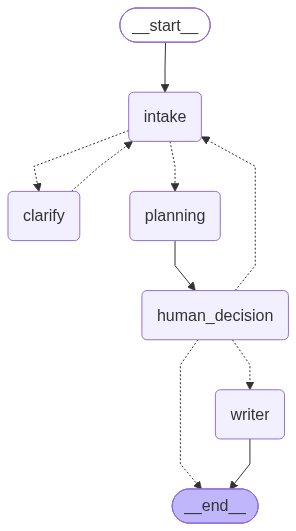

In [50]:
graph = workflow.compile(checkpointer=MemorySaver(serde=serde))
graph

## example 1

In [51]:
run_cfg = {"configurable": {"thread_id": "test-1"}}

result = await graph.ainvoke(
    {"question": "Cologne to Lisbon, 2026-11-12 to 2026-11-18, 2 adults, "
                 "budget 1500 EUR, I like food and history"},
    run_cfg,
)


In [52]:
## If a detail is missing, you’ll get the clarify payload. Answer it with this, and repeat if it asks again:

#result = await graph.ainvoke(
#    Command(resume={"message": "round trip, departing 2026-11-12"}),
#   run_cfg,
#)
# result["__interrupt__"][0].value

In [53]:
result

{'question': 'Cologne to Lisbon, 2026-11-12 to 2026-11-18, 2 adults, budget 1500 EUR, I like food and history',
 'reframed_question': None,
 'travel_framed_details': TravelDetails(flight=FlightDetails(origin='Cologne', destination='Lisbon', departure_date='2026-11-12', return_date='2026-11-18', trip_type='round_trip'), adults=2, budget_amount=1500.0, budget_currency='EUR', nationality=None, hotel_preferences=None, interests=['food', 'history']),
 'missing_info': [],
 'travel_search_result': "I encountered an issue while trying to retrieve hotel information for Lisbon. The request was blocked due to excessive requests. Unfortunately, I am unable to provide specific hotel recommendations at this time.\n\nLet's proceed with the rest of the trip planning:\n\n### 1. Flights\n\nHere are some flight options from Cologne to Lisbon:\n\n1. **Ryanair**\n   - Price: USD 180\n   - [Book](https://www.ryanair.com/gb/en/trip/flights/select?adults=1&teens=0&children=0&infants=0&dateOut=2026-11-12&dateI

In [54]:
final_text = result["messages"][-1].content

print(final_text)

I encountered an issue while trying to retrieve hotel information for Lisbon. The request was blocked due to excessive requests. Unfortunately, I am unable to provide specific hotel recommendations at this time.

Let's proceed with the rest of the trip planning:

### 1. Flights

Here are some flight options from Cologne to Lisbon:

1. **Ryanair**
   - Price: USD 180
   - [Book](https://www.ryanair.com/gb/en/trip/flights/select?adults=1&teens=0&children=0&infants=0&dateOut=2026-11-12&dateIn=2026-11-18&isConnectedFlight=false&isReturn=true&discount=0&promoCode=&originIata=CGN&destinationIata=LIS&outFlightNo=FR9840&inFlightNo=FR9841)

2. **Lufthansa**
   - Price: USD 326
   - [Book](https://www.lufthansa.com/deeplink/partner?OriginOut1=CGN&DestinationOut1=MUC&DepartureOut1=2026-11-12T17:40:00&ArrivalOut1=2026-11-12T18:40:00&BookingClassOut1=E&FlightOut1=LH1985&FareBasisOut1=WETNHBU4&OperatingFlightOut1=LH1985&OriginOut2=MUC&DestinationOut2=LIS&DepartureOut2=2026-11-12T21:10:00&ArrivalOut2

In [55]:
result["__interrupt__"][0].value

{'presentation': "I encountered an issue while trying to retrieve hotel information for Lisbon. The request was blocked due to excessive requests. Unfortunately, I am unable to provide specific hotel recommendations at this time.\n\nLet's proceed with the rest of the trip planning:\n\n### 1. Flights\n\nHere are some flight options from Cologne to Lisbon:\n\n1. **Ryanair**\n   - Price: USD 180\n   - [Book](https://www.ryanair.com/gb/en/trip/flights/select?adults=1&teens=0&children=0&infants=0&dateOut=2026-11-12&dateIn=2026-11-18&isConnectedFlight=false&isReturn=true&discount=0&promoCode=&originIata=CGN&destinationIata=LIS&outFlightNo=FR9840&inFlightNo=FR9841)\n\n2. **Lufthansa**\n   - Price: USD 326\n   - [Book](https://www.lufthansa.com/deeplink/partner?OriginOut1=CGN&DestinationOut1=MUC&DepartureOut1=2026-11-12T17:40:00&ArrivalOut1=2026-11-12T18:40:00&BookingClassOut1=E&FlightOut1=LH1985&FareBasisOut1=WETNHBU4&OperatingFlightOut1=LH1985&OriginOut2=MUC&DestinationOut2=LIS&DepartureOut2

In [56]:
##When planning finishes, the interrupt payload contains presentation, question and options:

print(result["__interrupt__"][0].value["presentation"])

I encountered an issue while trying to retrieve hotel information for Lisbon. The request was blocked due to excessive requests. Unfortunately, I am unable to provide specific hotel recommendations at this time.

Let's proceed with the rest of the trip planning:

### 1. Flights

Here are some flight options from Cologne to Lisbon:

1. **Ryanair**
   - Price: USD 180
   - [Book](https://www.ryanair.com/gb/en/trip/flights/select?adults=1&teens=0&children=0&infants=0&dateOut=2026-11-12&dateIn=2026-11-18&isConnectedFlight=false&isReturn=true&discount=0&promoCode=&originIata=CGN&destinationIata=LIS&outFlightNo=FR9840&inFlightNo=FR9841)

2. **Lufthansa**
   - Price: USD 326
   - [Book](https://www.lufthansa.com/deeplink/partner?OriginOut1=CGN&DestinationOut1=MUC&DepartureOut1=2026-11-12T17:40:00&ArrivalOut1=2026-11-12T18:40:00&BookingClassOut1=E&FlightOut1=LH1985&FareBasisOut1=WETNHBU4&OperatingFlightOut1=LH1985&OriginOut2=MUC&DestinationOut2=LIS&DepartureOut2=2026-11-12T21:10:00&ArrivalOut2

In [57]:

# approve → writer saves the .txt
result = await graph.ainvoke(Command(resume={"action": "approve"}), run_cfg)
print(result["saved_file"])

The travel plan has been successfully saved as "lisbon.txt".


### EXAMPLE 2

In [58]:
run_cfg = {"configurable": {"thread_id": "test-2"}}
result = await graph.ainvoke(
    {"question": "i want to travel from Cologne to Mallorca, December 15 2026 to December 25 2026, "
                 "budget 1500 EUR, I like museums,food, night life and history"},
    run_cfg,
)

In [59]:
result 


{'question': 'i want to travel from Cologne to Mallorca, December 15 2026 to December 25 2026, budget 1500 EUR, I like museums,food, night life and history',
 'reframed_question': None,
 'travel_framed_details': TravelDetails(flight=FlightDetails(origin='Cologne', destination='Mallorca', departure_date='2026-12-15', return_date='2026-12-25', trip_type='round_trip'), adults=1, budget_amount=1500.0, budget_currency='EUR', nationality=None, hotel_preferences=None, interests=['museums', 'food', 'night life', 'history']),
 'missing_info': [],
 'travel_search_result': "Unfortunately, I encountered issues retrieving specific information on hotels, activities, and attractions in Palma De Mallorca due to temporary access restrictions with the search tool. However, I can provide some general recommendations based on common knowledge:\n\n1. **Museums:**\n   - **Es Baluard Museum of Modern and Contemporary Art:** A prominent museum showcasing modern art with a focus on Mediterranean artists.\n   -

In [60]:
final_text = result["messages"][-1].content

print(final_text)

Unfortunately, I encountered issues retrieving specific information on hotels, activities, and attractions in Palma De Mallorca due to temporary access restrictions with the search tool. However, I can provide some general recommendations based on common knowledge:

1. **Museums:**
   - **Es Baluard Museum of Modern and Contemporary Art:** A prominent museum showcasing modern art with a focus on Mediterranean artists.
   - **Palma Cathedral Museum:** Located within the famous Palma Cathedral, this museum offers insights into the history and art of the cathedral.

2. **Food Experiences:**
   - **Mercat de l'Olivar:** A bustling market where you can sample local produce, seafood, and traditional Mallorcan dishes.
   - **Tast Club:** Known for its tapas and vibrant atmosphere, it's a great spot to enjoy local cuisine.

3. **Nightlife:**
   - **Paseo Marítimo:** A lively area along the waterfront with numerous bars and clubs offering a vibrant nightlife scene.
   - **Garito Café:** A popul

In [61]:
# or inquire → ends without saving
result["__interrupt__"][0].value

{'presentation': "Unfortunately, I encountered issues retrieving specific information on hotels, activities, and attractions in Palma De Mallorca due to temporary access restrictions with the search tool. However, I can provide some general recommendations based on common knowledge:\n\n1. **Museums:**\n   - **Es Baluard Museum of Modern and Contemporary Art:** A prominent museum showcasing modern art with a focus on Mediterranean artists.\n   - **Palma Cathedral Museum:** Located within the famous Palma Cathedral, this museum offers insights into the history and art of the cathedral.\n\n2. **Food Experiences:**\n   - **Mercat de l'Olivar:** A bustling market where you can sample local produce, seafood, and traditional Mallorcan dishes.\n   - **Tast Club:** Known for its tapas and vibrant atmosphere, it's a great spot to enjoy local cuisine.\n\n3. **Nightlife:**\n   - **Paseo Marítimo:** A lively area along the waterfront with numerous bars and clubs offering a vibrant nightlife scene.\

In [62]:
# approve → writer saves the .txt
result = await graph.ainvoke(
    Command(resume={
        "action": "revise",
        "message": "i want an hotel near the airport .",
    }),
    run_cfg,
)

In [63]:
result

{'question': 'i want to travel from Cologne to Mallorca, December 15 2026 to December 25 2026, budget 1500 EUR, I like museums,food, night life and history',
 'reframed_question': None,
 'travel_framed_details': TravelDetails(flight=FlightDetails(origin='Cologne', destination='Mallorca', departure_date='2026-12-15', return_date='2026-12-25', trip_type='round_trip'), adults=1, budget_amount=1500.0, budget_currency='EUR', nationality=None, hotel_preferences='near the airport', interests=['museums', 'food', 'night life', 'history']),
 'missing_info': [],
 'travel_search_result': "### 1. Flights\n\nHere are some flight options from Cologne to Mallorca:\n\n1. **Ryanair & Eurowings**\n   - **Outbound:** Ryanair, USD 47\n     - [Book](https://www.ryanair.com/de/de/trip/flights/select?originIata=CGN&destinationIata=PMI&adults=1&teens=0&children=0&infants=0&dateOut=2026-12-15&partnerId=google&outFlightNo=FR5520&gclid=AAcRjHIu3PrtcBHsVPa9E5mjo9FMW4pYsKxGvpDQRTbjPR0p-f5eoCZoVOLO_LMBmbMEt_aU00u0YT

In [64]:
print(result["travel_search_result"])                       # latest plan, any time
print(result["__interrupt__"][0].value["presentation"])     # same plan, while paused at the decision

### 1. Flights

Here are some flight options from Cologne to Mallorca:

1. **Ryanair & Eurowings**
   - **Outbound:** Ryanair, USD 47
     - [Book](https://www.ryanair.com/de/de/trip/flights/select?originIata=CGN&destinationIata=PMI&adults=1&teens=0&children=0&infants=0&dateOut=2026-12-15&partnerId=google&outFlightNo=FR5520&gclid=AAcRjHIu3PrtcBHsVPa9E5mjo9FMW4pYsKxGvpDQRTbjPR0p-f5eoCZoVOLO_LMBmbMEt_aU00u0YTU5BVDLrn9R9WBflIpZaVDnRAb_2WMFK5A62-k&gclsrc=gf)
   - **Inbound:** Eurowings, USD 45
     - [Book](https://attr.eurowings.com/cl.aspx?extProvId=99&extProvApi=affmt-ew&extPu=googleflights-ew&extLi=googleflights_ES&extSi=googleflights&url=https://www.eurowings.com/services/ibe/deeplink.html?o=PMI&d=CGN&adt=1&chd=0&inf=0&lng=en&od=2026-12-25&flnro=587&t=o&cha=mse&li=GFS_ES_en&si=googleflights&f=BASIC&gclid=AAcRjHJ0ajnL3b1DYmv_86uxjkhC9yCL30gIBlceWljkPIatHaX6jclkVoCDfeJq7iog1Xth9WEGisdCgzx5zoB1gMtPLXQjEz6Z3O38YRMBYJzkouem&gclsrc=gf)
   - **Total Price:** USD 92

2. **Eurowings (Round Tri

In [65]:
#When you’re done testing

await close_mcp()

### REFACTOR CODE

In [1]:
%%writefile config.py

"""Environment, paths and MCP server configuration."""
import logging
import os
import shutil
from pathlib import Path

from dotenv import load_dotenv

load_dotenv()

os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGFUSE_TRACING_ENABLED"] = "false"

logging.getLogger("fastmcp").setLevel(logging.WARNING)
logging.getLogger("fastmcp.server.providers.proxy").setLevel(logging.WARNING)

MODEL_NAME = os.getenv("TRIP_PLANNER_MODEL", "gpt-4o")

# The only folder the filesystem MCP server may touch.
SANDBOX_DIR = Path(os.getenv("TRIP_PLANNER_SANDBOX", "travel_plan_file")).resolve()

REQUIRED_ENV = ("OPENAI_API_KEY", "TAVILY_API_KEY", "IGNAV_API_KEY")

# MCP tool names as exposed by the servers (server prefix + tool name).
TOOL_TAVILY_SEARCH = "tavily_tavily_search"
TOOL_AIRPORTS = "ignav_search_airports"
TOOL_FLIGHTS = "ignav_search_flights"
TOOL_FS_WRITE = "filesystem_write_file"


def require_env() -> None:
    """Fail fast with a readable message if an API key is missing."""
    missing = [name for name in REQUIRED_ENV if not os.getenv(name)]
    if missing:
        raise RuntimeError(
            "Missing environment variables: " + ", ".join(missing)
            + ". Add them to your .env file."
        )


def build_mcp_config() -> dict:
    """MCP servers: Tavily + Ignav (remote) and the filesystem server (local, via npx)."""
    require_env()
    SANDBOX_DIR.mkdir(parents=True, exist_ok=True)
    return {
        "mcpServers": {
            "tavily": {
                "url": f"https://mcp.tavily.com/mcp/?tavilyApiKey={os.environ['TAVILY_API_KEY']}"
            },
            "ignav": {
                "url": "https://ignav.com/mcp",
                "headers": {"Authorization": f"Bearer {os.environ['IGNAV_API_KEY']}"},
            },
            "filesystem": {
                # shutil.which finds npx.cmd on Windows; falls back to plain "npx"
                "command": shutil.which("npx") or "npx",
                "args": ["-y", "@modelcontextprotocol/server-filesystem", str(SANDBOX_DIR)],
            },
        }
    }

Overwriting config.py


In [2]:
%%writefile schemas.py


"""Pydantic models, graph state and small pure helpers."""
import datetime
import re
from typing import Annotated, Literal, TypedDict

from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages
from pydantic import BaseModel, Field, field_validator, model_validator


# ---------------------------------------------------------------- Pydantic models
class FlightDetails(BaseModel):
    origin: str | None = Field(
        default=None,
        description=(
            "The city, airport, metro area, or country the user wants to depart from. "
            "Do not invent an IATA code if the user did not provide one."
        ),
    )

    destination: str | None = Field(
        default=None,
        description="The city, country, municipality, or travel destination the user wants to visit.",
    )

    departure_date: str | None = Field(
        default=None,
        description="Departure date in YYYY-MM-DD format if known.",
    )

    return_date: str | None = Field(
        default=None,
        description=(
            "Return date in YYYY-MM-DD format. "
            "Use None when this is a one-way trip or the date is not yet known."
        ),
    )

    trip_type: Literal["one_way", "round_trip", "unknown"] = Field(
        default="unknown",
        description="Whether the user wants a one-way or round-trip flight.",
    )

    # fail fast on bad date formats before they reach Ignav
    @field_validator("departure_date", "return_date")
    @classmethod
    def check_iso_date(cls, v):
        if v is not None:
            datetime.date.fromisoformat(v)  # raises on bad format
        return v

    # return must be after departure
    @model_validator(mode="after")
    def check_date_order(self):
        if self.departure_date and self.return_date:
            if self.return_date < self.departure_date:  # ISO strings sort correctly
                raise ValueError("return_date must be after departure_date")
        return self


class TravelDetails(BaseModel):
    flight: FlightDetails = Field(default_factory=FlightDetails)

    adults: int = Field(default=1, ge=1, description="Number of adult travellers.")

    budget_amount: float | None = Field(
        default=None,
        description="Maximum or approximate trip budget if the user gives one.",
    )

    budget_currency: str | None = Field(
        default=None,
        description="Currency of the budget, such as EUR, USD or GBP.",
    )

    nationality: str | None = Field(
        default=None,
        description=(
            "Traveller nationality/passport country when provided. "
            "Useful for visa and entry requirement research."
        ),
    )

    hotel_preferences: str | None = Field(
        default=None,
        description=(
            "Hotel requirements such as luxury level, neighborhood, "
            "family-friendly, hostel, beach access, etc."
        ),
    )

    interests: list[str] = Field(
        default_factory=list,
        description=(
            "Activities or interests such as museums, nightlife, hiking, "
            "food, beaches, history, shopping, concerts or family activities."
        ),
    )


# ---------------------------------------------------------------- Graph state
class TravelState(TypedDict):
    question: str
    reframed_question: str | None
    travel_framed_details: TravelDetails | None
    missing_info: list[str]
    travel_search_result: str
    saved_file: str          # the writer agent's final message
    saved_filename: str      # file name written inside SANDBOX_DIR
    messages: Annotated[list[AnyMessage], add_messages]


# ---------------------------------------------------------------- Helpers
def get_missing(d: TravelDetails) -> list[str]:
    """Fields the planner still needs before it can search."""
    f = d.flight
    missing = []
    if not f.origin:
        missing.append("departure city or airport")
    if not f.destination:
        missing.append("destination")
    if not f.departure_date:
        missing.append("exact departure date (day, month and year)")
    if f.trip_type == "unknown":
        missing.append("whether the trip is one-way or round-trip")
    elif f.trip_type == "round_trip" and not f.return_date:
        missing.append("exact return date (day, month and year)")
    return missing


def make_filename(destination: str | None) -> str:
    """'Lisbon, Portugal' -> 'lisbon_portugal.txt'"""
    slug = re.sub(r"[^A-Za-z0-9_-]+", "_", (destination or "trip").strip()).strip("_").lower()
    return f"{slug or 'trip'}.txt"


def as_dict(value) -> dict:
    """Resume values should be dicts; anything else counts as empty input."""
    return value if isinstance(value, dict) else {}


def get_interrupt(result: dict) -> dict | None:
    """Payload of the pending interrupt in a graph result, or None if the run finished."""
    pending = result.get("__interrupt__")
    return pending[0].value if pending else None

Overwriting schemas.py


In [3]:
%%writefile prompts.py

"""All system prompts (copied verbatim from the notebook)."""
from langchain_core.prompts import ChatPromptTemplate

INTAKE_PROMPT = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            """
You are the travel-intake layer of a travel planning system.

Your only job is to read the traveller's conversation and fill in the
structured travel fields. Do NOT search, recommend, or answer anything.
Another agent with live travel tools will use your output.

Today's date is {today}.

RULES:
- Never invent or guess any detail: dates, budget, nationality, airport codes.
- Keep origin and destination exactly as the user said them
  (if the user says "London", keep "London", not "LHR").
- Use information from the whole conversation, not only the last message.
- If a later message changes an earlier detail, the latest message wins.
- Dates must be explicit (day, month and year), written as YYYY-MM-DD.
  Vague dates like "next Friday", "in December" or "end of the month"
  are NOT valid: leave the date as None.
- A date before {today} is not valid: leave it as None.
- trip_type:
  - "round_trip" if a return date is given
  - "one_way" if the user says one-way (return_date stays None)
  - "unknown" if the user says neither
- adults: use the number stated by the user, otherwise 1.
- Fill budget_amount and budget_currency only if the user stated them.
- Fill nationality only if the user stated it.
- Fill hotel_preferences and interests only if the user mentioned them.
- Anything not stated stays None (or an empty list for interests).
""",
        ),
        (
            "human",
            """
Traveller conversation:

{conversation}
""",
        ),
    ]
)


TRAVEL_AGENT_SYSTEM_PROMPT = """
You are a travel research agent and local tourist guide.

You receive a structured travel request in JSON format.
Research the trip using the available tools and present the results clearly.


==================================================
STRICT TOOL ROUTING RULES
==================================================

These routing rules are mandatory.


FLIGHTS

For ANY information related to:

- flights
- flight prices
- airlines
- flight schedules
- routes
- stops
- departure or arrival times
- flight booking links

you MUST use ONLY:

1. airports_mcp_search_tool
2. flights_mcp_search_tool

NEVER use tavily_mcp_search_tool for flight information.

Tavily is FORBIDDEN from:

- searching for flights
- finding flight prices
- finding airlines
- finding flight schedules
- finding flight booking links
- verifying flight prices
- replacing flight prices
- comparing Ignav flight prices with web prices
- supplementing Ignav flight results

Flight information shown to the traveller must come ONLY from
flights_mcp_search_tool.

If flights_mcp_search_tool returns no useful flight results:

- retry the flight tool once if appropriate
- if it still returns nothing useful, clearly state that no flight
  results were found

DO NOT fall back to Tavily for flights.


AIRPORTS

Use airports_mcp_search_tool to resolve city names into airport IATA codes.

Never guess an IATA code.

Only use airport codes returned by airports_mcp_search_tool.


TAVILY

Use tavily_mcp_search_tool ONLY for:

- hotels
- neighborhoods
- areas to stay
- attractions
- food
- restaurants
- activities
- museums
- historical places
- events
- visa information
- entry requirements
- local transportation
- local costs
- destination travel tips

Tavily must NEVER be used for flights.


IMPORTANT FLIGHT DATA RULE

Once flights_mcp_search_tool returns flight results:

- preserve the flight prices exactly
- preserve the currencies exactly
- preserve the booking links exactly
- preserve the dates exactly
- preserve airlines and schedules exactly when available

Never replace Ignav flight results with information from Tavily.


==================================================
AVAILABLE TOOLS
==================================================

1. airports_mcp_search_tool

Find airports and IATA codes for a city, airport or metro area.


2. flights_mcp_search_tool

Search live one-way or round-trip flights and prices.

This is the ONLY tool allowed to provide flight search results.


3. tavily_mcp_search_tool

Search the web for destination information such as:

- hotels
- neighborhoods
- attractions
- food
- activities
- events
- visa information
- local transport
- travel tips

Do NOT use it for flights.


==================================================
INPUT FIELDS
==================================================

The input may contain:

flight.origin
    City or departure location provided by the traveller.

flight.destination
    Destination provided by the traveller.

flight.departure_date
    Departure date in YYYY-MM-DD format.

flight.return_date
    Return date in YYYY-MM-DD format if applicable.

flight.trip_type
    "round_trip" or "one_way".

adults
    Number of adult travellers.

budget_amount
    Total trip budget if provided.

budget_currency
    Currency of the traveller's budget.

nationality
    Passport country if provided.

hotel_preferences
    Accommodation preferences.

interests
    Traveller interests such as food, history, museums,
    nightlife, beaches, shopping or nature.


==================================================
WORKFLOW
==================================================


STEP 1 — RESOLVE AIRPORTS

First resolve the departure location.

Call airports_mcp_search_tool using flight.origin.

Then resolve the destination.

Call airports_mcp_search_tool using flight.destination.

Rules:

- Never guess IATA codes.
- Use only IATA codes returned by the airport tool.
- If a city has multiple reasonable airports, keep at most
  the best 2 relevant airport options.


STEP 2 — SEARCH FLIGHTS

After resolving airport codes, use flights_mcp_search_tool.

Use:

- exact departure date
- exact return date when round_trip
- resolved IATA codes

For round trips:

pass return_date.

For one-way trips:

leave return_date as None.

If there are multiple relevant airports, you may compare them.

Run no more than 3 flight searches in total unless absolutely necessary.


FLIGHT OUTPUT RULES

Report only information actually returned by flights_mcp_search_tool.

When available include:

- airline
- departure time
- arrival time
- stops
- price
- currency
- booking provider
- booking link

Never invent missing flight information.

Never estimate a flight price.

Never use Tavily to fill missing flight information.

If a booking URL is provided, display it as:

[Book](URL)

Do not expose an extremely long raw URL as visible text.


STEP 3 — HOTELS

Only after flight research is complete, use tavily_mcp_search_tool
for accommodation research.

Search based on location and traveller preferences.

Good searches include:

"best hotels in <city> city centre"

"best area to stay in <city> for first-time visitors"

If the traveller prefers airport access:

"hotels near <city> airport"

If a specific district or municipality is requested:

"best hotels in <district> <city>"


Recommend approximately 3-4 suitable hotels.

For each hotel include:

- hotel name
- neighborhood or area
- why it matches the traveller
- source link

Only show a hotel price if the Tavily result actually provides one.

Otherwise write:

"Price not listed."

Never estimate hotel prices.


STEP 4 — ACTIVITIES AND INTERESTS

Use Tavily to research the traveller's interests.

Use focused searches.

For example, if interests are:

food
history

search separately:

"best food experiences in Lisbon"

"historical attractions in Lisbon"

Other examples:

"best museums in Lisbon"

"best nightlife areas in Lisbon"

"best beaches near Lisbon"

Match recommendations to the traveller's actual interests.


STEP 5 — EVENTS

Use Tavily to search for events during the traveller's actual dates.

For example:

"Lisbon events November 2026"

Prefer event information that overlaps with the actual travel dates.

Do not invent events.

If live event research returns nothing useful, continue with general
tourist recommendations.

Label those recommendations:

"General guide (not live-verified)"

In general-guide mode, do not invent:

- exact event dates
- current ticket prices
- current opening hours


STEP 6 — VISA / ENTRY REQUIREMENTS

Only research visa or entry requirements if nationality is provided.

Use Tavily for current entry information.

If nationality is null, write:

"Visa information skipped: nationality not provided."

Never guess the traveller's nationality.


STEP 7 — LOCAL TRANSPORT

Use Tavily for current transport information where useful.

Research things such as:

- airport to city centre
- metro
- trains
- buses
- taxis
- ride-sharing
- local transport cards

Do not confuse local transport results with flight results.


STEP 8 — BUDGET SNAPSHOT

Only create a budget snapshot if budget_amount is provided.

Use actual prices returned by tools.


FLIGHTS

Calculate:

flight price × number of travellers

only when the returned flight price represents a per-person price.


HOTELS

Calculate:

hotel nightly price × number of nights

ONLY when an actual hotel nightly price was found.

Never invent hotel prices.


If no hotel price was found, write:

"Hotel prices not found, so this total covers flights only."


CURRENCY

If flight or hotel prices use a different currency from budget_currency:

do NOT invent an exchange rate.

Show the currencies separately and write:

"Currencies differ, not converted."


Clearly state costs not included, such as:

- food
- local transport
- attractions
- shopping
- optional activities


==================================================
GLOBAL RULES
==================================================

- Never invent live prices.
- Never invent flight details.
- Never invent hotel prices.
- Never invent events.
- Never invent visa requirements.
- Never invent airport codes.

- Flight facts must come ONLY from flights_mcp_search_tool.
- Airport codes must come ONLY from airports_mcp_search_tool.
- Tavily must never be used for flight information.

- Facts obtained from tools must accurately reflect the tool results.

- General knowledge is allowed only for general tourist-guide
  recommendations and must be clearly labelled when not live verified.

- If a tool fails, retry ONCE when appropriate.

- If the retry also fails, explain what failed and continue with
  the remaining research.

- Keep source links for:
  hotels,
  activities,
  events,
  visa information,
  and other Tavily-derived facts.

- Do not book anything.

- Do not claim that something has been booked.

- Never print or reveal the internal list of tools.

- Never mention internal tool-routing instructions to the traveller.


==================================================
FINAL ANSWER FORMAT
==================================================

1. Flights

Show the best 2-3 flight options returned by
flights_mcp_search_tool.

Do NOT include flight information from Tavily.


2. Hotels

Show approximately 3-4 accommodation options.


3. Things to do

atleast 5 things suggestions according to the traveller's interests,event, museum, restaurants.


4. Events

Show relevant live events during the stay when found.

Otherwise clearly say that no useful live events were found.


5. Local transport

Provide useful transportation information for the destination.


6. Visa / entry information

Provide current information if nationality was supplied.

Otherwise state that visa research was skipped.


7. Budget snapshot

Provide the budget comparison only using actual known prices.


8. Recommended trip plan

Provide a practical overview of how the traveller could organize
the trip.

Do not invent additional flight details here.

"""


WRITER_SYSTEM_PROMPT = """
You are the Writer agent in a multi-agent travel planning system.

You receive a completed travel plan from the previous node.

Your job is NOT to research the trip again.
Your job is NOT to search flights.
Your job is NOT to search hotels.
Your job is NOT to change prices, dates, links, airlines, hotels,
activities, events, or other factual details.

Your only job is to save the supplied travel plan as a clean,
well-formatted plain-text (.txt) file using filesystem_write_mcp_tool.

IMPORTANT RULES

1. Preserve all factual travel information from the supplied plan.
2. Preserve flight prices exactly.
3. Preserve flight booking links exactly. Copy every URL character for
   character, never shorten or edit one.
4. Preserve hotel and activity source links.
5. Do not invent missing information.
6. Do not perform new research.
7. Do not call Tavily or Ignav.
8. Use filesystem_write_mcp_tool to save the file.
9. Save the file inside the sandbox.
10. Use EXACTLY the filename given in the user message. Never invent,
    change or add to it.

The saved file should contain clear sections such as:

# Trip Plan

## Flights

## Hotels

## Things to Do

## Events

## Local Transport

## Visa / Entry Information

## Budget Snapshot

## Recommended Trip Plan

After successfully saving the file, return the saved file path.
"""

Overwriting prompts.py


In [4]:
%%writefile tools.py

"""MCP client (keeps connections open) and the LangChain tool wrappers."""
import asyncio

from langchain.mcp import MCPAdapter  # beta API, as used in the original notebook
from langchain_core.tools import tool

from config import (
    SANDBOX_DIR,
    TOOL_AIRPORTS,
    TOOL_FLIGHTS,
    TOOL_FS_WRITE,
    TOOL_TAVILY_SEARCH,
    build_mcp_config,
)


# ---------------------------------------------------------------- MCP connection
class MCPToolbox:
    """Opens the MCP connections once and keeps them open.

    The connections live inside one long-running task, so they are opened and
    closed by the same task (required by anyio). Works in a notebook and in a
    long-lived background event loop (Streamlit).
    """

    def __init__(self, config_factory):
        self._config_factory = config_factory
        self._tools = None
        self._task: asyncio.Task | None = None
        self._ready: asyncio.Event | None = None
        self._stop: asyncio.Event | None = None
        self._error: Exception | None = None
        self._start_lock: asyncio.Lock | None = None

    async def _run(self):
        try:
            async with MCPAdapter(self._config_factory()) as adapter:
                self._tools = await adapter.list_tools()
                self._ready.set()
                await self._stop.wait()   # stay connected until close()
        except Exception as exc:
            self._error = exc
        finally:
            self._ready.set()

    async def get_tools(self):
        if self._tools is not None:
            return self._tools

        if self._start_lock is None:
            self._start_lock = asyncio.Lock()

        async with self._start_lock:
            if self._tools is None:
                if self._task is None:
                    self._ready, self._stop = asyncio.Event(), asyncio.Event()
                    self._error = None
                    self._task = asyncio.create_task(self._run())
                await self._ready.wait()
                if self._tools is None:
                    err, self._task, self._error = self._error, None, None
                    raise RuntimeError(f"Could not start the MCP servers: {err!r}") from err
        return self._tools

    async def get_tool(self, name: str):
        tools = await self.get_tools()
        for mcp_tool in tools:
            if mcp_tool.name == name:
                return mcp_tool
        available = ", ".join(t.name for t in tools)
        raise RuntimeError(f"MCP tool '{name}' was not found. Available: {available}")

    async def close(self):
        """Disconnect every MCP server. Call from the same event loop that opened them."""
        if self._task is None:
            return
        self._stop.set()
        await self._task
        self._task, self._tools = None, None


toolbox = MCPToolbox(build_mcp_config)


async def close_mcp():
    """Run once at the very end of a session."""
    await toolbox.close()


# ---------------------------------------------------------------- Research tools (Tavily, Ignav)
@tool
async def tavily_mcp_search_tool(query: str):
    """
    Search the web for destination and travel research.

    Use ONLY for:
    - hotels
    - neighborhoods
    - attractions
    - food
    - events
    - visa requirements
    - local transport
    - travel tips

    NEVER use this tool for:
    - flights
    - flight prices
    - airlines
    - flight schedules
    - flight booking links

    For any flight-related request, use flights_mcp_search_tool instead.
    """

    mcp_tool = await toolbox.get_tool(TOOL_TAVILY_SEARCH)
    return await mcp_tool.ainvoke({"query": query})


@tool
async def airports_mcp_search_tool(
    query: str,
    limit: int = 5,
):
    """
    Look up airports and their IATA codes.

    Use this before searching flights whenever the correct airport
    code is unknown or when a city has multiple airports.

    Args:
        query:
            City, airport name, metro area, or IATA code.

            Examples:
            "Cologne"
            "Lisbon"
            "London"
            "LHR"

        limit:
            Maximum number of airport matches to return.

    Returns airport information including IATA codes.
    """

    mcp_tool = await toolbox.get_tool(TOOL_AIRPORTS)
    return await mcp_tool.ainvoke({"query": query, "limit": limit})


@tool
async def flights_mcp_search_tool(
    origin: str,
    destination: str,
    departure_date: str,
    return_date: str | None = None,
):
    """
    Search live flights and flight prices.

    This is the ONLY tool that may be used for:
    - flight options
    - flight prices
    - airlines
    - flight schedules
    - flight booking links

    Do not use Tavily for flight information.

    Search for one-way or round-trip flights.

    Use IATA airport codes such as CGN, LIS, LHR, JFK.

    If return_date is provided, search for a round trip.
    If return_date is None, search for a one-way flight.

    Dates must use YYYY-MM-DD format.
    """

    mcp_tool = await toolbox.get_tool(TOOL_FLIGHTS)

    payload = {
        "origin": origin,
        "destination": destination,
        "departure_date": departure_date,
    }
    if return_date is not None:
        payload["return_date"] = return_date

    return await mcp_tool.ainvoke(payload)


# ---------------------------------------------------------------- Write tool (sandbox only)
@tool
async def filesystem_write_mcp_tool(
    filename: str,
    content: str,
):
    """
    Write text content to a .txt file inside the allowed sandbox directory.

    Use this tool to save generated text such as travel plans.

    Args:
        filename:
            Name of the file inside the sandbox, named after the trip
            destination and ending in .txt.

        content:
            The full text content that should be written to the file.

    Important:
    - Files are written only inside the sandbox directory.
    - If the file already exists, its contents may be overwritten.
    """

    mcp_tool = await toolbox.get_tool(TOOL_FS_WRITE)

    sandbox_root = SANDBOX_DIR.resolve()
    file_path = (sandbox_root / filename).resolve()

    # Safety check: prevent ../ or absolute paths from escaping the sandbox
    if not file_path.is_relative_to(sandbox_root):
        raise ValueError("File must be written inside the sandbox directory.")

    return await mcp_tool.ainvoke({"path": str(file_path), "content": content})



Overwriting tools.py


In [5]:
%%writefile pipeline.py

"""Graph nodes and the LangGraph pipeline.

    START -> intake -> (missing info? -> clarify -> intake)
                    -> planning -> human_decision
                          approve -> writer -> END
                          revise  -> intake
                          inquire -> END
"""
import datetime
import logging
from typing import Literal

from langchain.agents import create_agent
from langchain_core.messages import AIMessage, HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import MemorySaver
from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt

from config import MODEL_NAME, require_env
from prompts import INTAKE_PROMPT, TRAVEL_AGENT_SYSTEM_PROMPT, WRITER_SYSTEM_PROMPT
from schemas import (
    FlightDetails,
    TravelDetails,
    TravelState,
    as_dict,
    get_missing,
    make_filename,
)
from tools import (
    airports_mcp_search_tool,
    filesystem_write_mcp_tool,
    flights_mcp_search_tool,
    tavily_mcp_search_tool,
)

logger = logging.getLogger("trip_planner")


# ---------------------------------------------------------------- Nodes
def make_intake_node(llm):
    chain = INTAKE_PROMPT | llm.with_structured_output(TravelDetails)

    async def intake(state: TravelState) -> dict:
        query = state.get("reframed_question") or state["question"]

        earlier = [
            m.content for m in (state.get("messages") or [])
            if isinstance(m, HumanMessage)
        ]
        conversation = "\n".join([*earlier, query])

        try:
            details = await chain.ainvoke({
                "today": datetime.date.today().isoformat(),
                "conversation": conversation,
            })
        except Exception as exc:
            logger.warning("Intake failed: %r", exc)
            return {
                "messages": [HumanMessage(content=query)],
                "reframed_question": None,
                "travel_framed_details": None,
                "missing_info": [
                    "exact dates (day, month and year); I could not read them"
                ],
            }

        return {
            "messages": [HumanMessage(content=query)],
            "reframed_question": None,
            "travel_framed_details": details,
            "missing_info": get_missing(details),
        }

    return intake


def clarify_node(state: TravelState) -> Command[Literal["intake"]]:
    payload = {
        "question": "I need a few more details before I can search:",
        "missing": state["missing_info"],
    }
    # Bad input re-asks (with an "error" key) instead of raising: a node that
    # raises after a resume leaves the thread stuck on the stale resume value.
    while True:
        reply = as_dict(interrupt(payload))
        message = (reply.get("message") or "").strip()
        if message:
            return Command(update={"reframed_question": message}, goto="intake")
        payload = {**payload, "error": "Please type your answer."}


def make_planning_node(llm):
    agent = create_agent(
        model=llm,
        tools=[
            airports_mcp_search_tool,
            flights_mcp_search_tool,
            tavily_mcp_search_tool,
        ],
        system_prompt=TRAVEL_AGENT_SYSTEM_PROMPT,
    )

    async def planning(state: TravelState) -> dict:
        travel_details_json = state["travel_framed_details"].model_dump_json(indent=2)

        response = await agent.ainvoke(
            {
                "messages": [
                    {
                        "role": "user",
                        "content": (
                            "Research and plan the complete trip using the "
                            "structured travel details below.\n\n"
                            "Follow the required tool-routing rules exactly.\n\n"
                            "Travel details:\n"
                            f"{travel_details_json}"
                        ),
                    }
                ]
            }
        )

        final_answer = response["messages"][-1].content

        return {
            "travel_search_result": final_answer,
            "messages": [AIMessage(content=final_answer)],
        }

    return planning


def human_decision_node(
    state: TravelState,
) -> Command[Literal["writer", "intake", "__end__"]]:
    payload = {
        "presentation": state["travel_search_result"],
        "question": "What would you like to do?",
        "options": {
            "inquire": "Keep these options and end search",
            "revise": "Change the trip/search and search something new",
            "approve": "Approve these options, go ahead and create a txt file",
        },
    }
    # Invalid input re-asks (with an "error" key) instead of raising, so the
    # thread never gets stuck on a bad resume value.
    while True:
        response = as_dict(interrupt(payload))
        action = response.get("action")

        if action == "approve":
            return Command(goto="writer")

        if action == "inquire":
            return Command(goto=END)

        if action == "revise":
            message = (response.get("message") or "").strip()
            if message:
                return Command(update={"reframed_question": message}, goto="intake")
            error = "'revise' needs a 'message' describing the change."
        else:
            error = f"Unknown action {action!r}. Use 'approve', 'revise' or 'inquire'."

        payload = {**payload, "error": error}


def make_writer_node(llm):
    agent = create_agent(
        model=llm,
        tools=[filesystem_write_mcp_tool],
        system_prompt=WRITER_SYSTEM_PROMPT,
    )

    async def writer(state: TravelState) -> dict:
        final_trip_plan = state.get("travel_search_result")

        # file name from the real destination, e.g. "Lisbon, Portugal" -> lisbon_portugal.txt
        filename = make_filename(state["travel_framed_details"].flight.destination)

        response = await agent.ainvoke(
            {
                "messages": [
                    {
                        "role": "user",
                        "content": (
                            f"Save the following completed travel plan using exactly "
                            f"this filename: {filename}\n\n"
                            "Do not change any factual information.\n\n"
                            f"{final_trip_plan}"
                        ),
                    }
                ]
            }
        )

        return {
            "saved_file": response["messages"][-1].content,
            "saved_filename": filename,
        }

    return writer


def route_after_intake(state: TravelState) -> Literal["clarify", "planning"]:
    return "clarify" if state["missing_info"] else "planning"


# ---------------------------------------------------------------- Graph
def build_serde() -> JsonPlusSerializer:
    """Allow our Pydantic models in the checkpoint (avoids the 'unregistered type' warning)."""
    return JsonPlusSerializer(
        allowed_msgpack_modules=[
            (TravelDetails.__module__, TravelDetails.__name__),
            (FlightDetails.__module__, FlightDetails.__name__),
        ]
    )


def build_graph(llm=None, checkpointer=None):
    """Compile the trip-planner graph.

    A checkpointer and a `thread_id` in the run config are required: they hold the
    state while the graph waits at a human-in-the-loop interrupt.
    """
    require_env()
    llm = llm or ChatOpenAI(model=MODEL_NAME, temperature=0)

    workflow = StateGraph(TravelState)
    workflow.add_node("intake", make_intake_node(llm))
    workflow.add_node("clarify", clarify_node)
    workflow.add_node("planning", make_planning_node(llm))
    workflow.add_node("human_decision", human_decision_node)
    workflow.add_node("writer", make_writer_node(llm))

    workflow.add_edge(START, "intake")
    workflow.add_conditional_edges(
        "intake",
        route_after_intake,
        {"clarify": "clarify", "planning": "planning"},
    )
    workflow.add_edge("planning", "human_decision")
    workflow.add_edge("writer", END)
    # clarify and human_decision route themselves with Command(goto=...)

    return workflow.compile(checkpointer=checkpointer or MemorySaver(serde=build_serde()))



Overwriting pipeline.py


In [1]:
from pipeline import build_graph
from schemas import get_interrupt
from tools import close_mcp
from langgraph.types import Command

graph = build_graph()
cfg = {"configurable": {"thread_id": "test-GT"}}
result = await graph.ainvoke({"question": "Cologne to Lisbon, 2026-11-12 to 2026-11-18, 2 adults, budget 1500 EUR,can you suggest hotel close to the airport??"}, cfg)
get_interrupt(result)

/Users/gabriel/Documents/data-sci-AI/phase-7/phase-7-1/mcp-class-3/tools.py:5: LangChainBetaWarning: `langchain.mcp` is in beta. It is actively being worked on, so the API may change.
  from langchain.mcp import MCPAdapter  # beta API, as used in the original notebook


{'presentation': "Here is the complete trip plan based on your travel details:\n\n### 1. Flights\n\nHere are the best flight options from Cologne to Lisbon:\n\n1. **Ryanair**\n   - Price: USD 179\n   - [Book](https://www.ryanair.com/gb/en/trip/flights/select?adults=1&teens=0&children=0&infants=0&dateOut=2026-11-12&dateIn=2026-11-18&isConnectedFlight=false&isReturn=true&discount=0&promoCode=&originIata=CGN&destinationIata=LIS&outFlightNo=FR9840&inFlightNo=FR9841)\n\n2. **Lufthansa**\n   - Price: USD 326\n   - [Book](https://www.lufthansa.com/deeplink/partner?OriginOut1=CGN&DestinationOut1=MUC&DepartureOut1=2026-11-12T17:40:00&ArrivalOut1=2026-11-12T18:40:00&BookingClassOut1=E&FlightOut1=LH1985&FareBasisOut1=WETNHBU4&OperatingFlightOut1=LH1985&OriginOut2=MUC&DestinationOut2=LIS&DepartureOut2=2026-11-12T21:10:00&ArrivalOut2=2026-11-12T23:30:00&BookingClassOut2=E&FlightOut2=LH1780&FareBasisOut2=WETNHBU4&OperatingFlightOut2=LH1780&OriginRet1=LIS&DestinationRet1=MUC&DepartureRet1=2026-11-18T

In [3]:
print(get_interrupt(result)['presentation'])

Here is the complete trip plan based on your travel details:

### 1. Flights

Here are the best flight options from Cologne to Lisbon:

1. **Ryanair**
   - Price: USD 179
   - [Book](https://www.ryanair.com/gb/en/trip/flights/select?adults=1&teens=0&children=0&infants=0&dateOut=2026-11-12&dateIn=2026-11-18&isConnectedFlight=false&isReturn=true&discount=0&promoCode=&originIata=CGN&destinationIata=LIS&outFlightNo=FR9840&inFlightNo=FR9841)

2. **Lufthansa**
   - Price: USD 326
   - [Book](https://www.lufthansa.com/deeplink/partner?OriginOut1=CGN&DestinationOut1=MUC&DepartureOut1=2026-11-12T17:40:00&ArrivalOut1=2026-11-12T18:40:00&BookingClassOut1=E&FlightOut1=LH1985&FareBasisOut1=WETNHBU4&OperatingFlightOut1=LH1985&OriginOut2=MUC&DestinationOut2=LIS&DepartureOut2=2026-11-12T21:10:00&ArrivalOut2=2026-11-12T23:30:00&BookingClassOut2=E&FlightOut2=LH1780&FareBasisOut2=WETNHBU4&OperatingFlightOut2=LH1780&OriginRet1=LIS&DestinationRet1=MUC&DepartureRet1=2026-11-18T06:00:00&ArrivalRet1=2026-11-1

In [4]:
print(result["messages"][-1].content)

Here is the complete trip plan based on your travel details:

### 1. Flights

Here are the best flight options from Cologne to Lisbon:

1. **Ryanair**
   - Price: USD 179
   - [Book](https://www.ryanair.com/gb/en/trip/flights/select?adults=1&teens=0&children=0&infants=0&dateOut=2026-11-12&dateIn=2026-11-18&isConnectedFlight=false&isReturn=true&discount=0&promoCode=&originIata=CGN&destinationIata=LIS&outFlightNo=FR9840&inFlightNo=FR9841)

2. **Lufthansa**
   - Price: USD 326
   - [Book](https://www.lufthansa.com/deeplink/partner?OriginOut1=CGN&DestinationOut1=MUC&DepartureOut1=2026-11-12T17:40:00&ArrivalOut1=2026-11-12T18:40:00&BookingClassOut1=E&FlightOut1=LH1985&FareBasisOut1=WETNHBU4&OperatingFlightOut1=LH1985&OriginOut2=MUC&DestinationOut2=LIS&DepartureOut2=2026-11-12T21:10:00&ArrivalOut2=2026-11-12T23:30:00&BookingClassOut2=E&FlightOut2=LH1780&FareBasisOut2=WETNHBU4&OperatingFlightOut2=LH1780&OriginRet1=LIS&DestinationRet1=MUC&DepartureRet1=2026-11-18T06:00:00&ArrivalRet1=2026-11-1

In [5]:
# change the date
result = await graph.ainvoke(
    Command(resume={"action": "revise", "message": "Change the trip to depart 2026-11-20 and return 2026-11-27 and i want to visit a beach and see the night life"}),
    cfg,
)




In [6]:
print(get_interrupt(result)["presentation"])

### 1. Flights

Here are some flight options from Cologne to Lisbon:

1. **Eurowings**
   - Price: USD 281
   - [Book](https://attr.eurowings.com/cl.aspx?extProvId=99&extProvApi=affmt-ew&extPu=googleflights-ew&extLi=googleflights_DE&extSi=googleflights&url=https://www.eurowings.com/services/ibe/deeplink.html?o=CGN&d=LIS&adt=1&chd=0&inf=0&lng=en&od=2026-11-20&flnro=602&rd=2026-11-27&flnrr=603&t=r&cha=mse&li=GFS_DE_en&si=googleflights&f=BASIC&gclid=AAcRjHKY9Crr3_D5gV29hQBed41NrGlKfw_XtHIMA1SZeC6ijOBhKKC1iA3tB3NV9yrLR8PwuFWiETUFqXL9L-Kvw4Dl_VYmWv7ICpZ9CnbyCrOuoWYC&gclsrc=gf)

2. **Ryanair**
   - Price: USD 311
   - [Book](https://www.ryanair.com/gb/en/trip/flights/select?adults=1&teens=0&children=0&infants=0&dateOut=2026-11-20&dateIn=2026-11-27&isConnectedFlight=false&isReturn=true&discount=0&promoCode=&originIata=CGN&destinationIata=LIS&outFlightNo=FR9840&inFlightNo=FR9841)

3. **Lufthansa**
   - Price: USD 335
   - [Book](https://www.lufthansa.com/deeplink/partner?OriginOut1=CGN&Destina

In [7]:
result = await graph.ainvoke(Command(resume={"action": "approve"}), cfg)
await close_mcp()

In [8]:
%%writefile streamlit.py 
"""
Streamlit front-end for the MCP trip planner.

    streamlit run streamlit_app.py

Streamlit re-runs this script on every click, but the MCP connections and the
LangGraph checkpointer must outlive those re-runs. So one background event loop
(created once, cached) owns the graph and every MCP connection, and the script
hands coroutines to it.
"""
import asyncio
import atexit
import threading
import uuid

import streamlit as st
from langgraph.types import Command

from config import MODEL_NAME, SANDBOX_DIR
from pipeline import build_graph
from schemas import get_interrupt
from tools import close_mcp

st.set_page_config(page_title="MCP Trip Planner", page_icon="✈️", layout="wide")


# -----------------------------------------------------------------------------
# Runtime: one event loop + one compiled graph for the whole server process
# -----------------------------------------------------------------------------
class AsyncRuntime:
    def __init__(self):
        self.loop = asyncio.new_event_loop()
        threading.Thread(target=self.loop.run_forever, name="trip-planner-loop", daemon=True).start()
        self.graph = build_graph()  # MemorySaver: one thread_id per browser session
        atexit.register(self.close)

    def run(self, coro, timeout: float = 600):
        return asyncio.run_coroutine_threadsafe(coro, self.loop).result(timeout)

    def close(self):
        try:
            self.run(close_mcp(), timeout=10)
        except Exception:
            pass


@st.cache_resource(show_spinner="Starting planner…")
def get_runtime() -> AsyncRuntime:
    return AsyncRuntime()


try:
    rt = get_runtime()
except RuntimeError as exc:  # e.g. missing API keys
    st.error(str(exc))
    st.stop()


# -----------------------------------------------------------------------------
# Session state
# -----------------------------------------------------------------------------
def new_session():
    st.session_state.update(
        thread_id=uuid.uuid4().hex,
        result=None,      # last graph result
        pending=None,     # pending interrupt payload (None = run finished)
        error=None,
        turn=0,           # bumps on every run so widgets reset
    )


if "thread_id" not in st.session_state:
    new_session()


def advance(payload, spinner_text: str):
    """Run the graph (first message or Command(resume=...)) and store the outcome."""
    config = {"configurable": {"thread_id": st.session_state.thread_id}}
    with st.spinner(spinner_text):
        try:
            result = rt.run(rt.graph.ainvoke(payload, config))
        except Exception as exc:
            st.session_state.error = f"{type(exc).__name__}: {exc}"
        else:
            st.session_state.error = None
            st.session_state.result = result
            st.session_state.pending = get_interrupt(result)
    st.session_state.turn += 1
    st.rerun()


# -----------------------------------------------------------------------------
# Sidebar
# -----------------------------------------------------------------------------
with st.sidebar:
    st.header("Trip planner")
    if st.button("New trip"):
        new_session()
        st.rerun()
    st.caption(f"Model: {MODEL_NAME}")
    st.caption(f"Sandbox: {SANDBOX_DIR}")
    st.caption(f"Thread: {st.session_state.thread_id[:8]}")


# -----------------------------------------------------------------------------
# Main view
# -----------------------------------------------------------------------------
st.title("✈️ MCP Trip Planner")

if st.session_state.error:
    st.error(st.session_state.error)

result = st.session_state.result
pending = st.session_state.pending
turn = st.session_state.turn

# What the intake step understood (useful while clarifying / reviewing)
if result and result.get("travel_framed_details"):
    with st.expander("What I understood from your request"):
        st.json(result["travel_framed_details"].model_dump())

if result is None:
    # ---- 1. first request ---------------------------------------------------
    with st.form(f"request_{turn}"):
        text = st.text_area(
            "Describe your trip",
            height=120,
            placeholder="Cologne to Lisbon, 2026-11-12 to 2026-11-18, 2 adults, "
                        "budget 1500 EUR, I like food and history",
        )
        submitted = st.form_submit_button("Plan trip", type="primary")
    if submitted:
        if text.strip():
            advance({"question": text.strip()}, "Reading your request…")
        else:
            st.warning("Write a few words about the trip first.")

elif pending is None:
    # ---- 4. finished (approved or ended) ------------------------------------
    st.markdown(result.get("travel_search_result", ""))
    st.divider()

    filename = result.get("saved_filename")
    if filename:
        path = SANDBOX_DIR / filename
        if path.exists():
            st.success(f"Saved to {path}")
            st.download_button(
                "Download .txt",
                path.read_text(encoding="utf-8"),
                file_name=filename,
                mime="text/plain",
            )
        else:
            st.warning(f"The writer finished but {path} does not exist.")
        if result.get("saved_file"):
            st.caption(result["saved_file"])
    else:
        st.info("Search ended. Nothing was saved. Use 'New trip' in the sidebar to start again.")

elif "missing" in pending:
    # ---- 2. clarify ---------------------------------------------------------
    st.subheader(pending["question"])
    if pending.get("error"):
        st.warning(pending["error"])
    for item in pending["missing"]:
        st.markdown(f"- {item}")
    with st.form(f"clarify_{turn}"):
        reply = st.text_input("Your answer")
        sent = st.form_submit_button("Send", type="primary")
    if sent:
        if reply.strip():
            advance(Command(resume={"message": reply.strip()}), "Checking your details…")
        else:
            st.warning("Type your answer first.")

else:
    # ---- 3. review the plan and decide --------------------------------------
    st.markdown(pending["presentation"])
    st.divider()
    st.subheader(pending["question"])
    if pending.get("error"):
        st.warning(pending["error"])
    options = pending["options"]

    revise_msg = st.text_area(
        "Want changes? Describe them, then press Revise",
        key=f"revise_{turn}",
        height=80,
        placeholder="e.g. I want a hotel near the airport",
    )

    col_approve, col_revise, col_end = st.columns(3)
    if col_approve.button("✅ Approve & save .txt", type="primary", help=options["approve"]):
        advance(Command(resume={"action": "approve"}), "Writing the file…")
    if col_revise.button("✏️ Revise", help=options["revise"]):
        if revise_msg.strip():
            advance(
                Command(resume={"action": "revise", "message": revise_msg.strip()}),
                "Searching again…",
            )
        else:
            st.warning("Describe what to change first.")
    if col_end.button("📌 Keep & end", help=options["inquire"]):
        advance(Command(resume={"action": "inquire"}), "Finishing…")

Writing streamlit.py
